# Lens 1–9 Como — match report

UEFA Champions League 2026/27, league phase, 4 November 2026.

**A record night:** Como's nine goals equal the most ever scored by one team in a Champions League match (Bayern Munich 9–2 Dinamo Zagreb, 2024). The eight-goal margin equals the competition's biggest win (Liverpool 8–0 Beşiktaş, 2007; Real Madrid 8–0 Malmö, 2015), and it is the biggest away win in Champions League history.

Each chart from the working notebook (`Lens_vs_Como.ipynb`) is rewritten here as a reusable `draw_...(ax, team)` function, and the last cell puts them all on one page and saves it as `match_report.png`. Needs `Lens_Como.csv` in the same folder.

## Setup

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from mplsoccer import Pitch

HOME, AWAY = "Lens", "Como"
FOCUS = AWAY                     # the team drawn attacking left -> right on shared pitches
STAR = "Tasos Douvikas"          # man of the match

COLOURS = {"Lens": "#c8102e", "Como": "#0a2d6e"}
CMAPS = {"Lens": "YlOrRd", "Como": "Blues"}

## Load the events and build the extra columns

Distance to goal (in metres), progressive passes, set pieces, the guessed receiver of each pass, and the xT added by every completed pass.

In [2]:
events = pd.read_csv("Lens_Como.csv")

# distance to goal, in metres
events["dist_start"] = np.sqrt(((100 - events["x"]) * 1.05)**2 + ((50 - events["y"]) * 0.68)**2)
events["dist_end"] = np.sqrt(((100 - events["end_x"]) * 1.05)**2 + ((50 - events["end_y"]) * 0.68)**2)
events["is_progressive"] = events["dist_end"] <= 0.75 * events["dist_start"]

# set pieces, as a COLUMN so filtered tables keep it
events["set_piece"] = events["qualifiers"].str.contains("CornerTaken|ThrowIn", na=False)

# guessed receiver: the next event's player and team
events["next_player"] = events["player"].shift(-1)
events["next_team"] = events["team"].shift(-1)

# completed passes for both teams, with xT added
passes_ok = events[(events["type"] == "Pass") & (events["outcome_type"] == "Successful")].copy()

xt_grid = pd.read_csv(
    "https://raw.githubusercontent.com/mckayjohns/youtube-videos/main/data/xT_Grid.csv",
    header=None,
).values

passes_ok["start_col"] = np.clip((passes_ok["x"] / 100 * 12).astype(int), 0, 11)
passes_ok["start_row"] = np.clip((passes_ok["y"] / 100 * 8).astype(int), 0, 7)
passes_ok["end_col"] = np.clip((passes_ok["end_x"] / 100 * 12).astype(int), 0, 11)
passes_ok["end_row"] = np.clip((passes_ok["end_y"] / 100 * 8).astype(int), 0, 7)
passes_ok["xt"] = np.clip(
    xt_grid[passes_ok["end_row"], passes_ok["end_col"]]
    - xt_grid[passes_ok["start_row"], passes_ok["start_col"]],
    0, None,
)


def completed_passes(team):
    return passes_ok[passes_ok["team"] == team]


def flip_if_needed(df, team):
    """Shared pitches: the FOCUS team attacks left -> right, the other team is mirrored."""
    df = df.copy()
    if team != FOCUS:
        df["x"] = 100 - df["x"]
        df["y"] = 100 - df["y"]
    return df

Quick check — `[events, Lens completed passes, Como completed passes, Lens xT, Como xT]`:

In [3]:
[
    len(events),
    len(completed_passes(HOME)),
    len(completed_passes(AWAY)),
    round(completed_passes(HOME)["xt"].sum(), 2),
    round(completed_passes(AWAY)["xt"].sum(), 2),
]

[1736, 430, 611, np.float64(1.17), np.float64(1.79)]

## Pass end zones

In [4]:
def draw_pass_end_zones(ax, team):
    passes = completed_passes(team)

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    stats = pitch.bin_statistic(passes["end_x"], passes["end_y"],
                                statistic="count", bins=(6, 5), normalize=True)
    pitch.heatmap(stats, ax=ax, cmap=CMAPS[team], edgecolors="white")
    pitch.label_heatmap(stats, ax=ax, str_format="{:.0%}",
                        ha="center", va="center", fontsize=9)

    ax.set_title(f"{team}: where {len(passes)} completed passes ended")

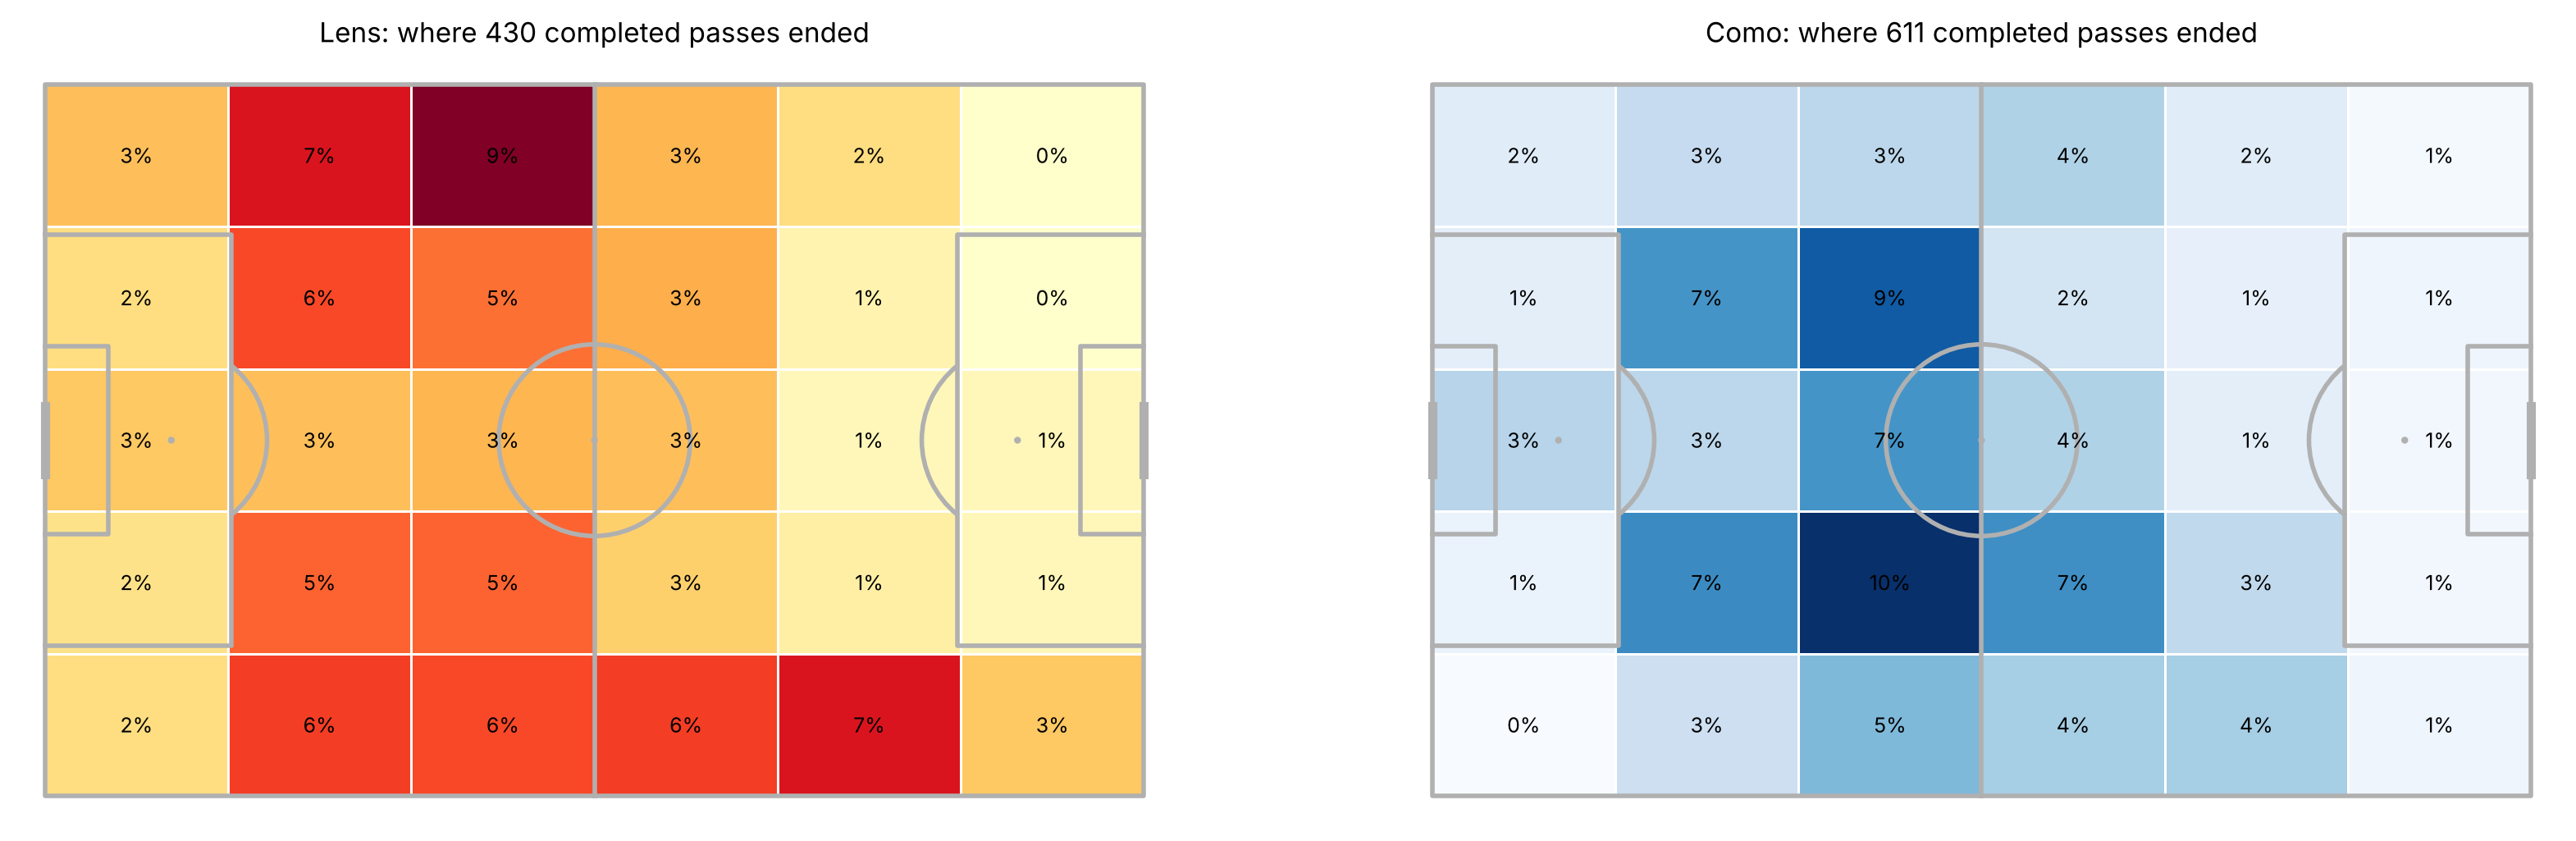

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_pass_end_zones(axes[0], HOME)
draw_pass_end_zones(axes[1], AWAY)
plt.show()

## Progressive passes

In [6]:
def draw_progressive(ax, team):
    passes = completed_passes(team)
    prog = passes[(passes["is_progressive"]) & (~passes["set_piece"])]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    pitch.arrows(prog["x"], prog["y"], prog["end_x"], prog["end_y"],
                 ax=ax, width=1.5, headwidth=5, color=COLOURS[team])

    ax.set_title(f"{team}: {len(prog)} progressive passes")

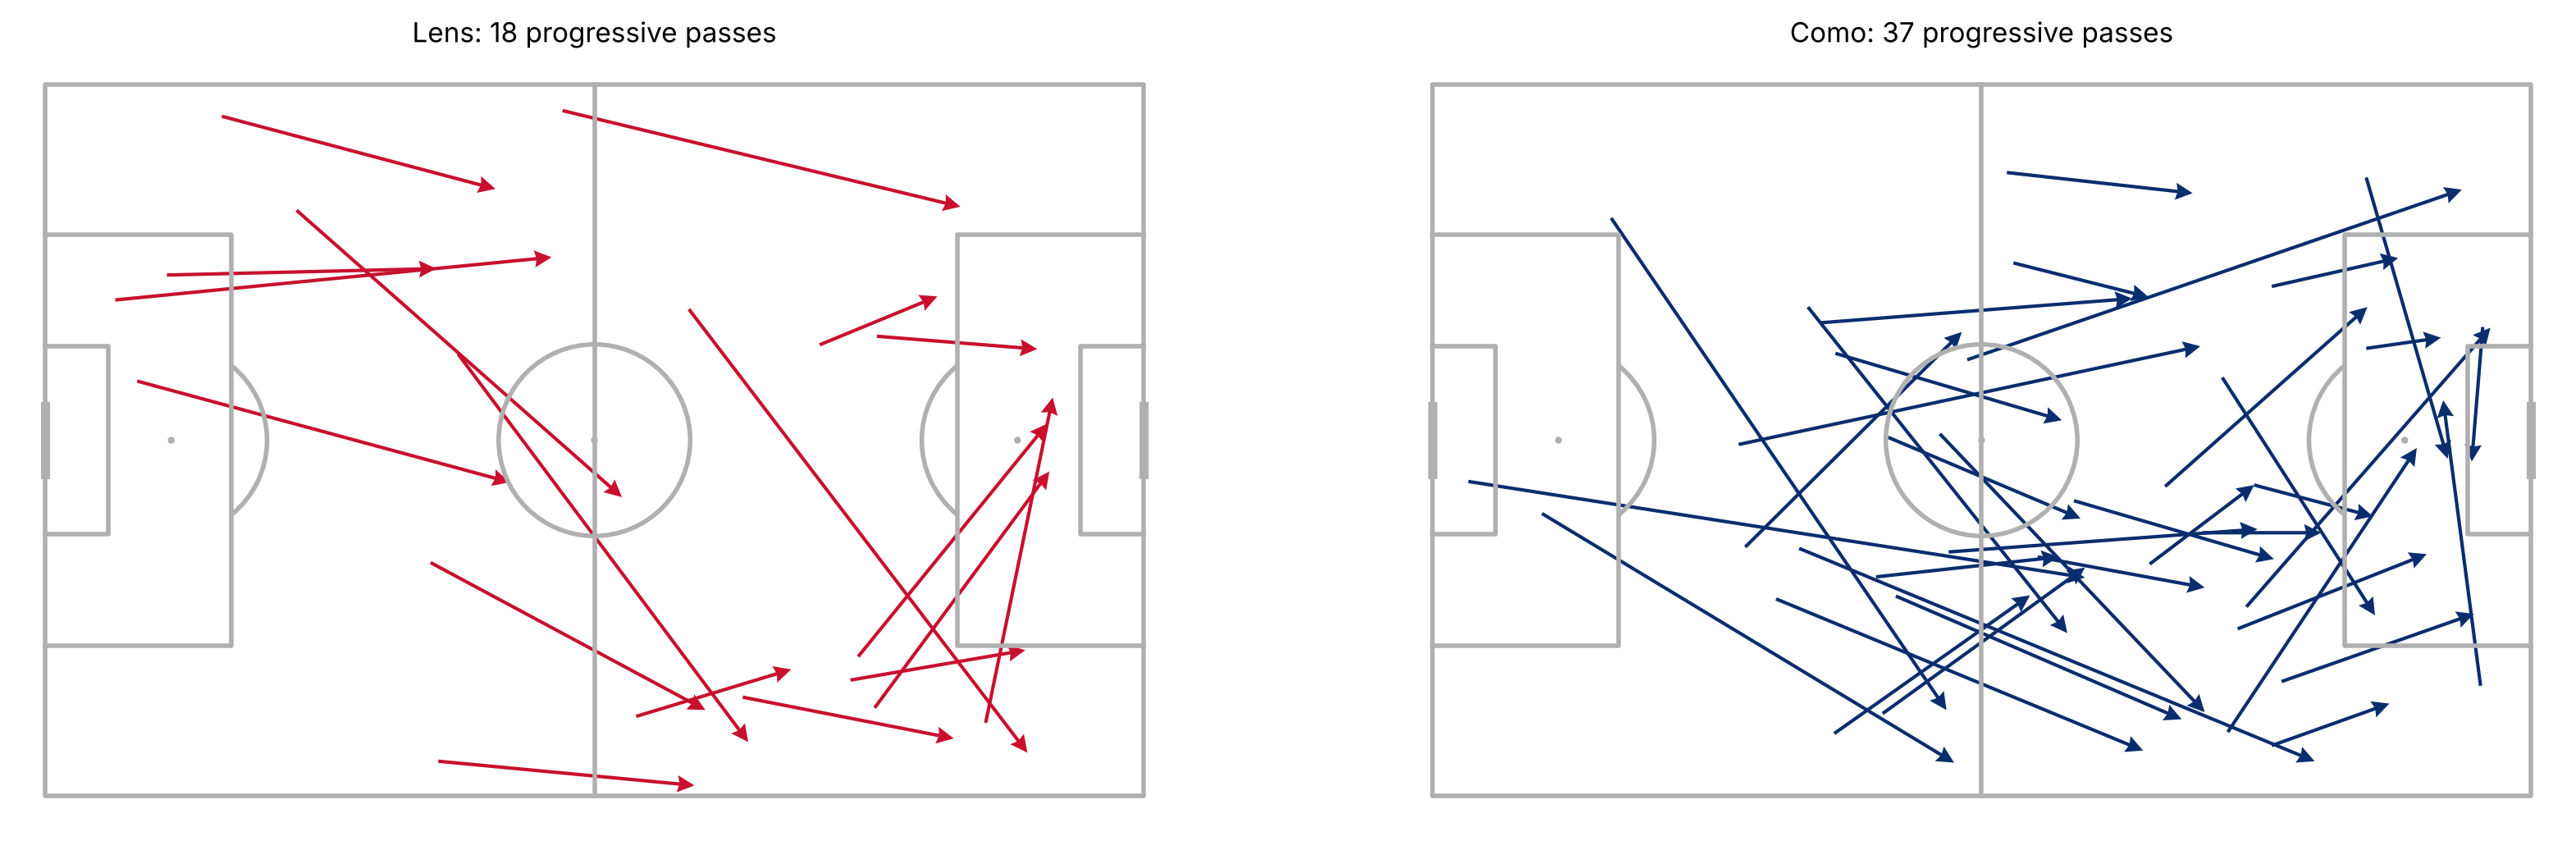

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_progressive(axes[0], HOME)
draw_progressive(axes[1], AWAY)
plt.show()

## Shot map (both teams)

In [8]:
def draw_shot_map_both(ax):
    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    for team in [HOME, AWAY]:
        shots = flip_if_needed(events[(events["team"] == team) & (events["is_shot"] == True)], team)
        goals = shots[shots["is_goal"] == True]

        pitch.scatter(shots["x"], shots["y"], ax=ax, s=150, color="none",
                      edgecolors=COLOURS[team], linewidth=2)
        pitch.scatter(goals["x"], goals["y"], ax=ax, s=300, color=COLOURS[team],
                      edgecolors="black",
                      label=f"{team} ({len(shots)} shots, {len(goals)} goals)")

    ax.legend(loc="upper center", fontsize=10)
    ax.set_title("Shot map (filled = goal)")

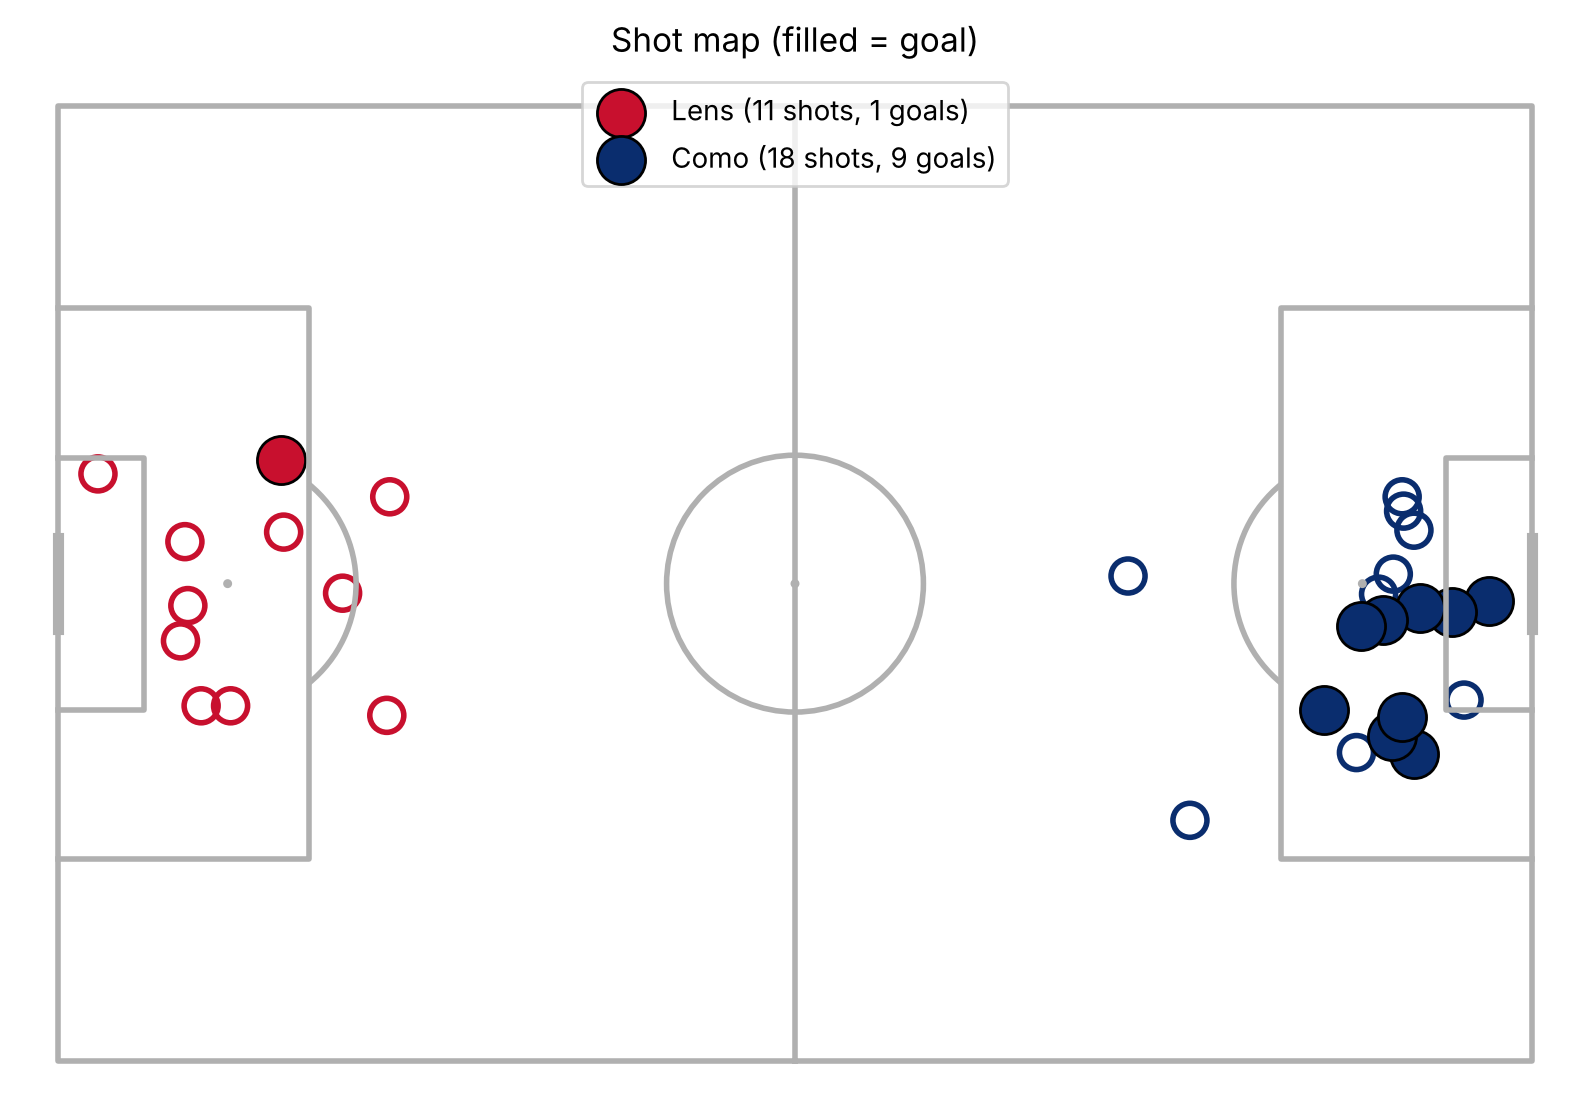

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_shot_map_both(ax)
plt.show()

## Chance creation

In [10]:
def draw_chance_creation(ax, team):
    kp = events[(events["team"] == team) & (events["type"] == "Pass")
                & (events["qualifiers"].str.contains("KeyPass", na=False))]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    stats = pitch.bin_statistic(kp["x"], kp["y"], statistic="count", bins=(6, 5))   # where they STARTED
    pitch.heatmap(stats, ax=ax, cmap=CMAPS[team], edgecolors="white")
    pitch.label_heatmap(stats, ax=ax, str_format="{:.0f}", ha="center", va="center", fontsize=9)

    pitch.arrows(kp["x"], kp["y"], kp["end_x"], kp["end_y"],
                 ax=ax, width=2, headwidth=5, color="black", zorder=3)

    ax.set_title(f"{team}: {len(kp)} chances created")

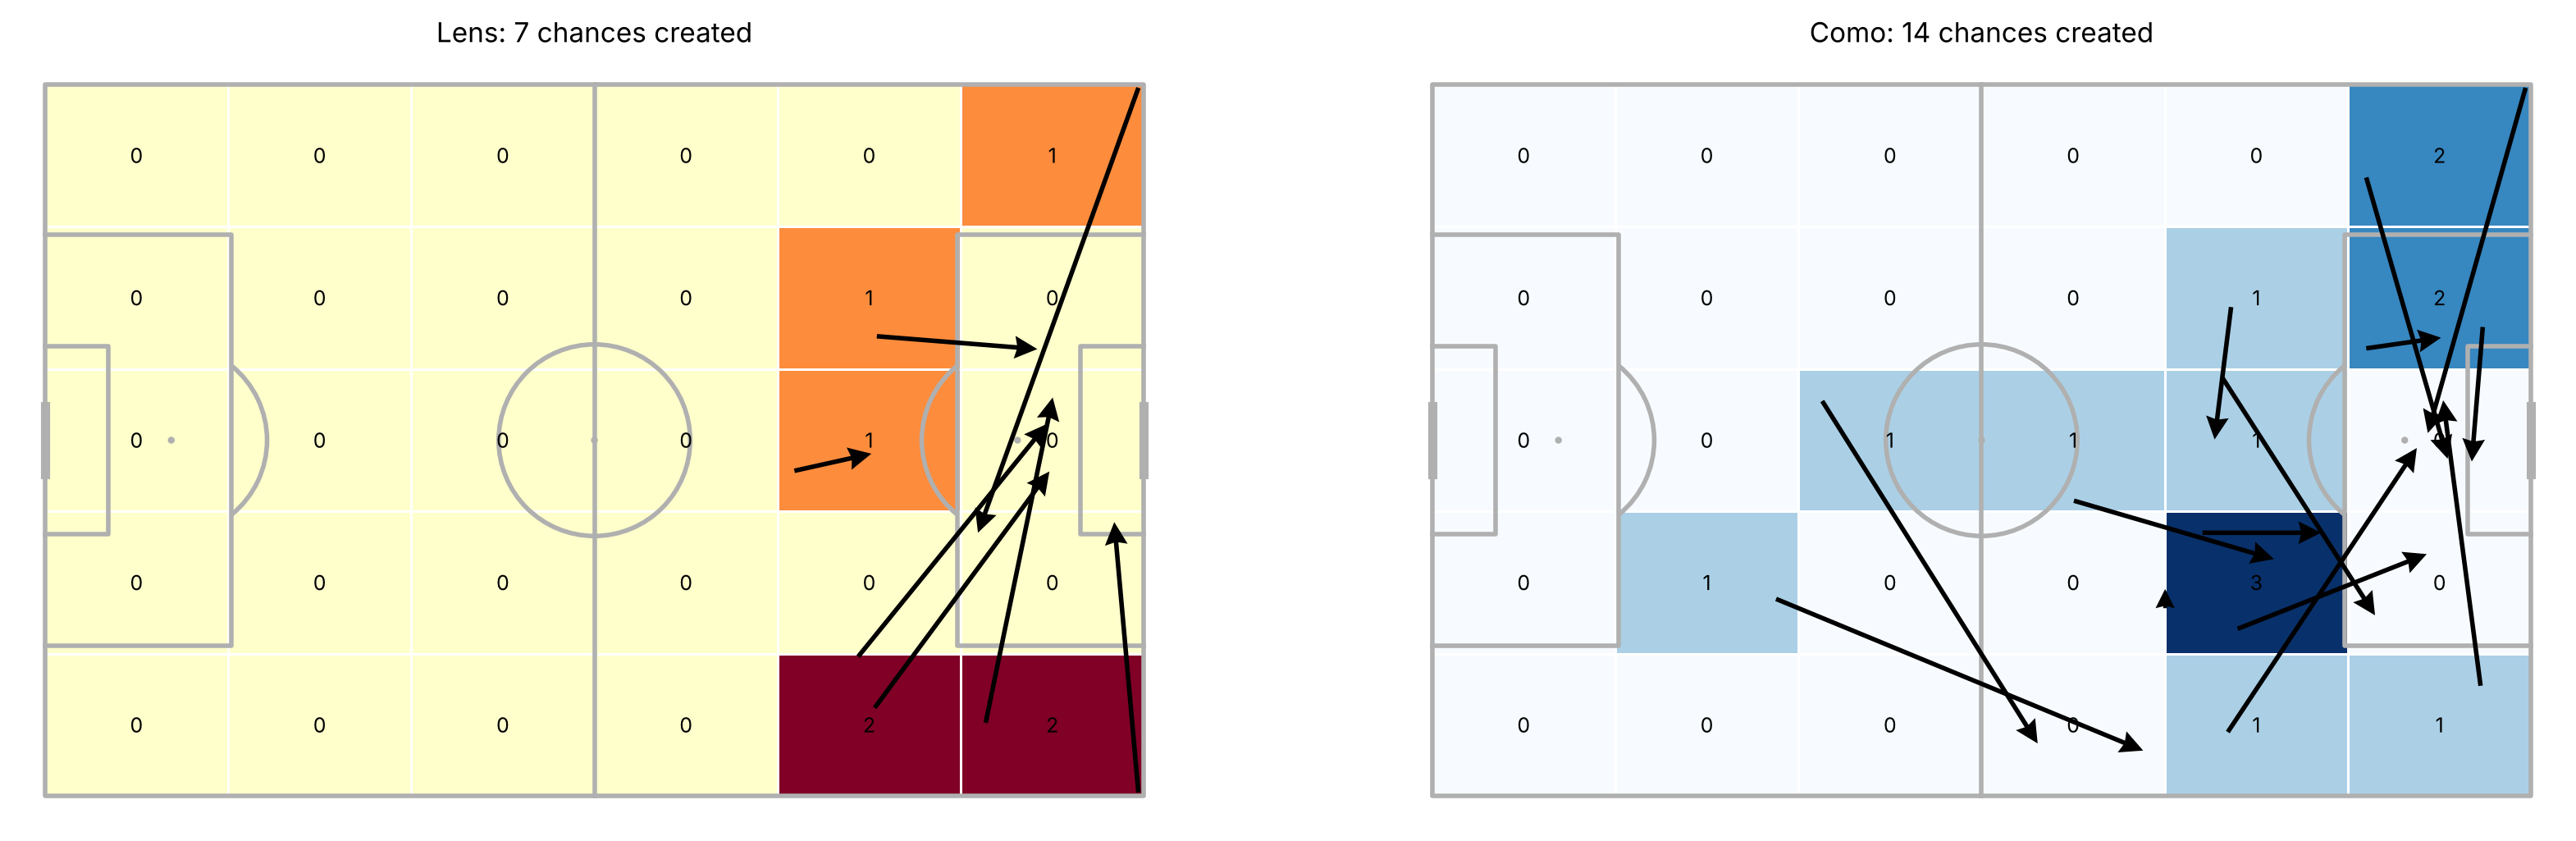

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_chance_creation(axes[0], HOME)
draw_chance_creation(axes[1], AWAY)
plt.show()

## Defensive actions

In [12]:
def draw_defensive_block(ax, team):
    def_types = ["Tackle", "Interception", "BallRecovery", "Clearance", "BlockedPass", "Aerial"]
    d = events[(events["team"] == team) & (events["type"].isin(def_types))]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    pitch.kdeplot(d["x"], d["y"], ax=ax, fill=True, levels=50,
                  cmap=CMAPS[team], thresh=0.05)

    ax.set_title(f"{team}: {len(d)} defensive actions")

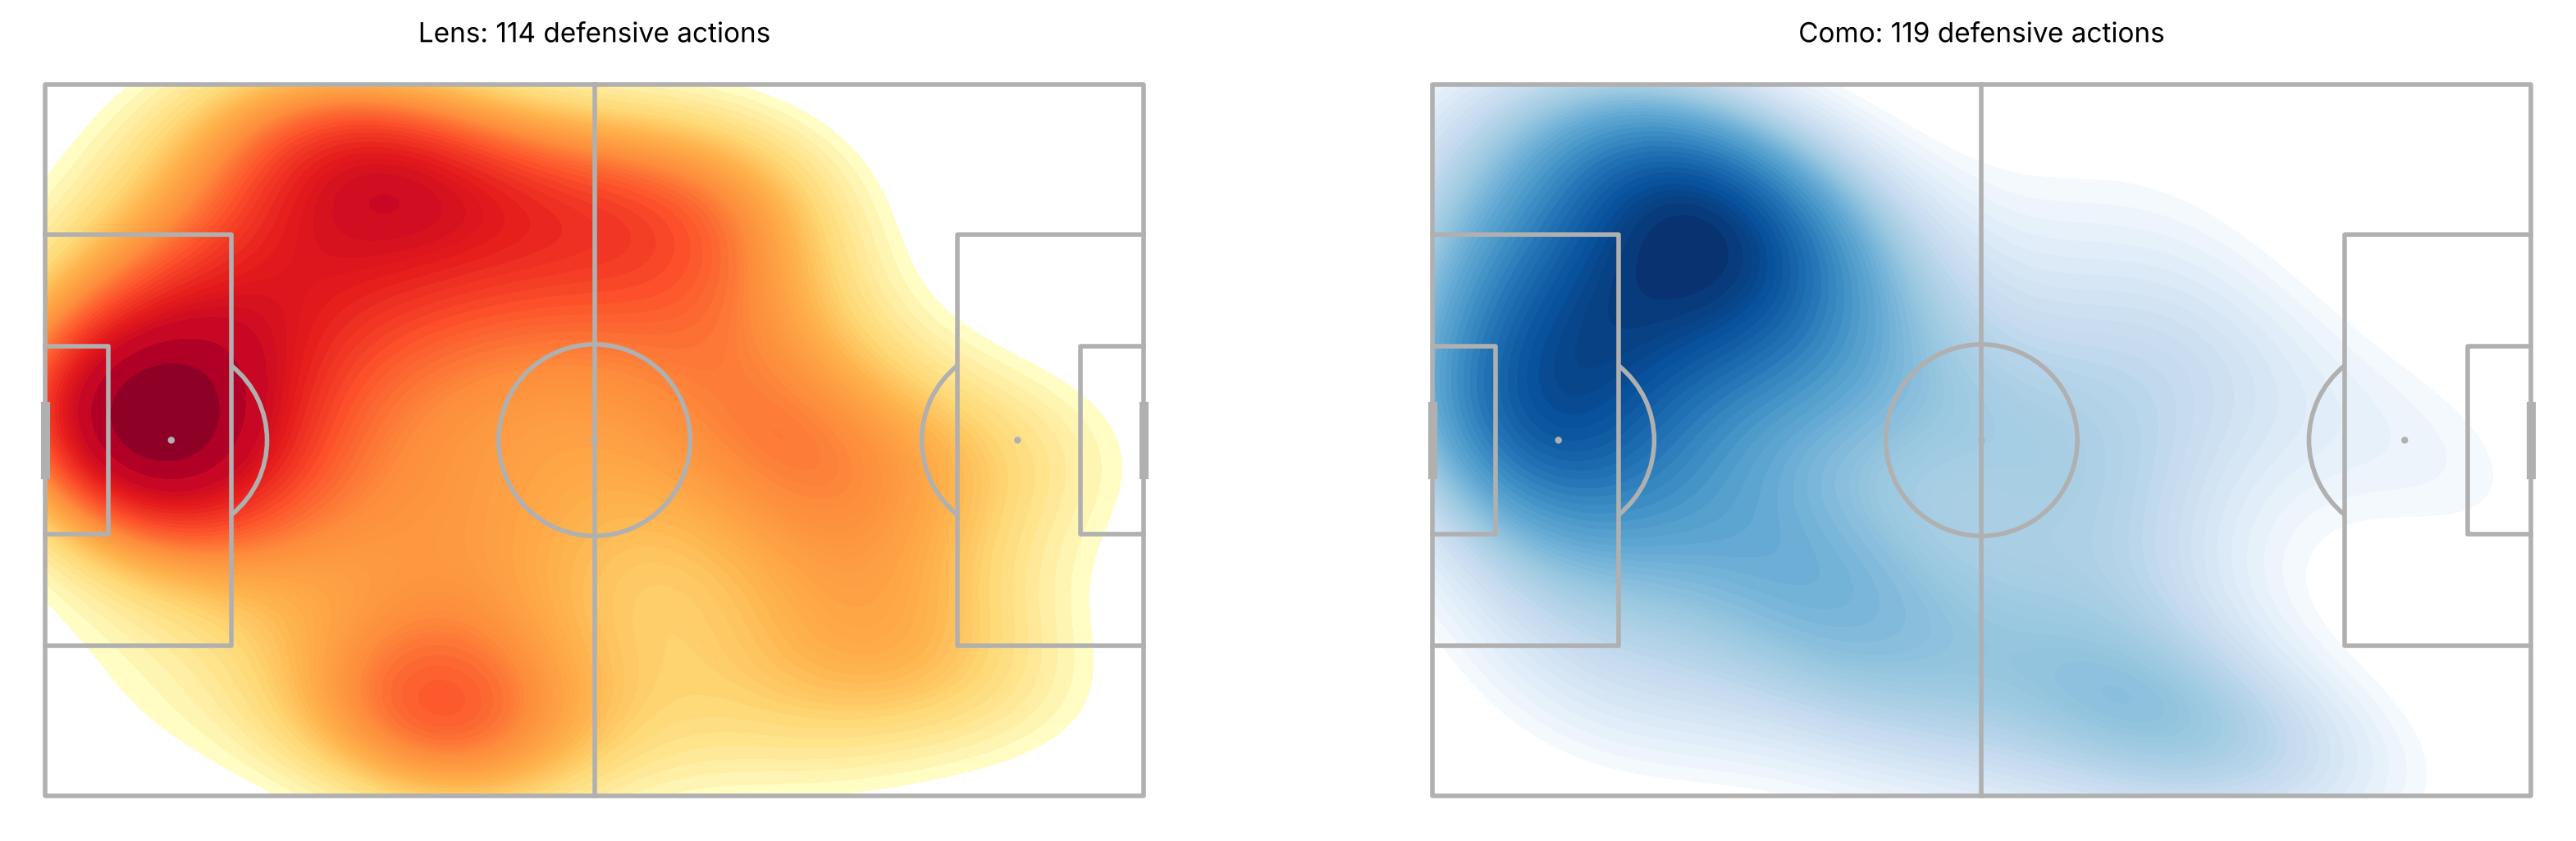

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_defensive_block(axes[0], HOME)
draw_defensive_block(axes[1], AWAY)
plt.show()

## High turnovers

In [14]:
def draw_high_turnovers(ax):
    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    wins = events["type"].isin(["BallRecovery", "Interception"])
    won_tackle = (events["type"] == "Tackle") & (events["outcome_type"] == "Successful")
    near_goal = events["dist_start"] <= 40

    for team in [HOME, AWAY]:
        ht = flip_if_needed(events[(events["team"] == team) & (wins | won_tackle) & near_goal], team)
        pitch.scatter(ht["x"], ht["y"], ax=ax, s=150, color=COLOURS[team],
                      edgecolors="black", label=f"{team} ({len(ht)})")

    ax.legend(loc="upper center", fontsize=10)
    ax.set_title("High turnovers: ball won within 40m of goal")

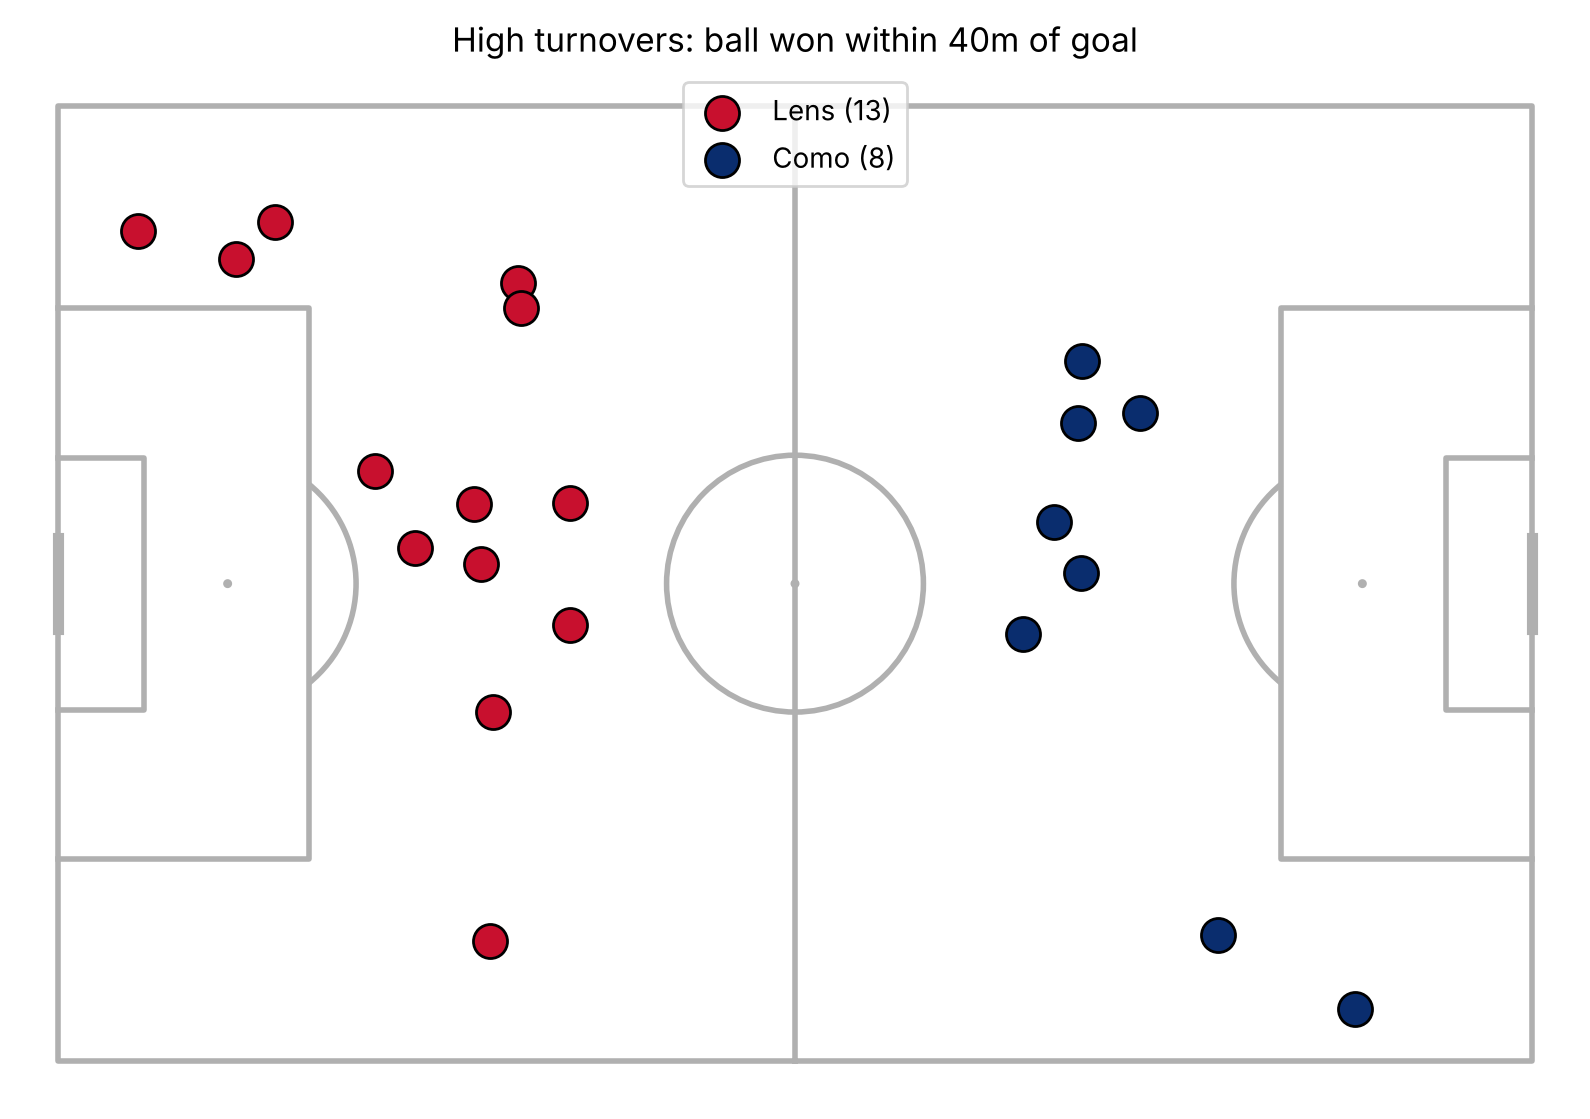

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_high_turnovers(ax)
plt.show()

## Passing networks

In [16]:
def draw_passing_network(ax, team):
    # 1. first substitution for this team
    subs = events[(events["type"] == "SubstitutionOn") & (events["team"] == team)]
    first_sub = subs["minute"].min()

    # 2. passes before the first sub that reached a teammate
    starters = completed_passes(team)
    starters = starters[(starters["minute"] < first_sub) & (starters["next_team"] == team)]

    # 3. dots: average position and number of passes per player
    avg = starters.groupby("player").agg(x=("x", "mean"), y=("y", "mean"), n=("x", "size"))

    # 4. lines: each passer -> receiver pair made 3+ times
    pairs = starters.groupby(["player", "next_player"]).size().reset_index(name="count")
    pairs = pairs[pairs["count"] >= 3]

    pairs["x_start"] = pairs["player"].map(avg["x"])
    pairs["y_start"] = pairs["player"].map(avg["y"])
    pairs["x_end"] = pairs["next_player"].map(avg["x"])
    pairs["y_end"] = pairs["next_player"].map(avg["y"])
    pairs = pairs.dropna()

    # 5. stop arrows 80% of the way, so the heads aren't hidden under the dots
    pairs["x_arrow"] = pairs["x_start"] + 0.8 * (pairs["x_end"] - pairs["x_start"])
    pairs["y_arrow"] = pairs["y_start"] + 0.8 * (pairs["y_end"] - pairs["y_start"])

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    for _, row in pairs.iterrows():
        pitch.arrows(row["x_start"], row["y_start"], row["x_arrow"], row["y_arrow"],
                     ax=ax, width=row["count"] * 0.5, headwidth=4, headlength=4,
                     color=COLOURS[team], alpha=0.6, zorder=1)

    pitch.scatter(avg["x"], avg["y"], ax=ax, s=avg["n"] * 15, color="white",
                  edgecolors=COLOURS[team], linewidth=2, zorder=2)

    for player, pos in avg.iterrows():
        pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4),
                       ax=ax, ha="center", fontsize=9, zorder=3)

    ax.set_title(f"{team}: passing network (until minute {first_sub})")

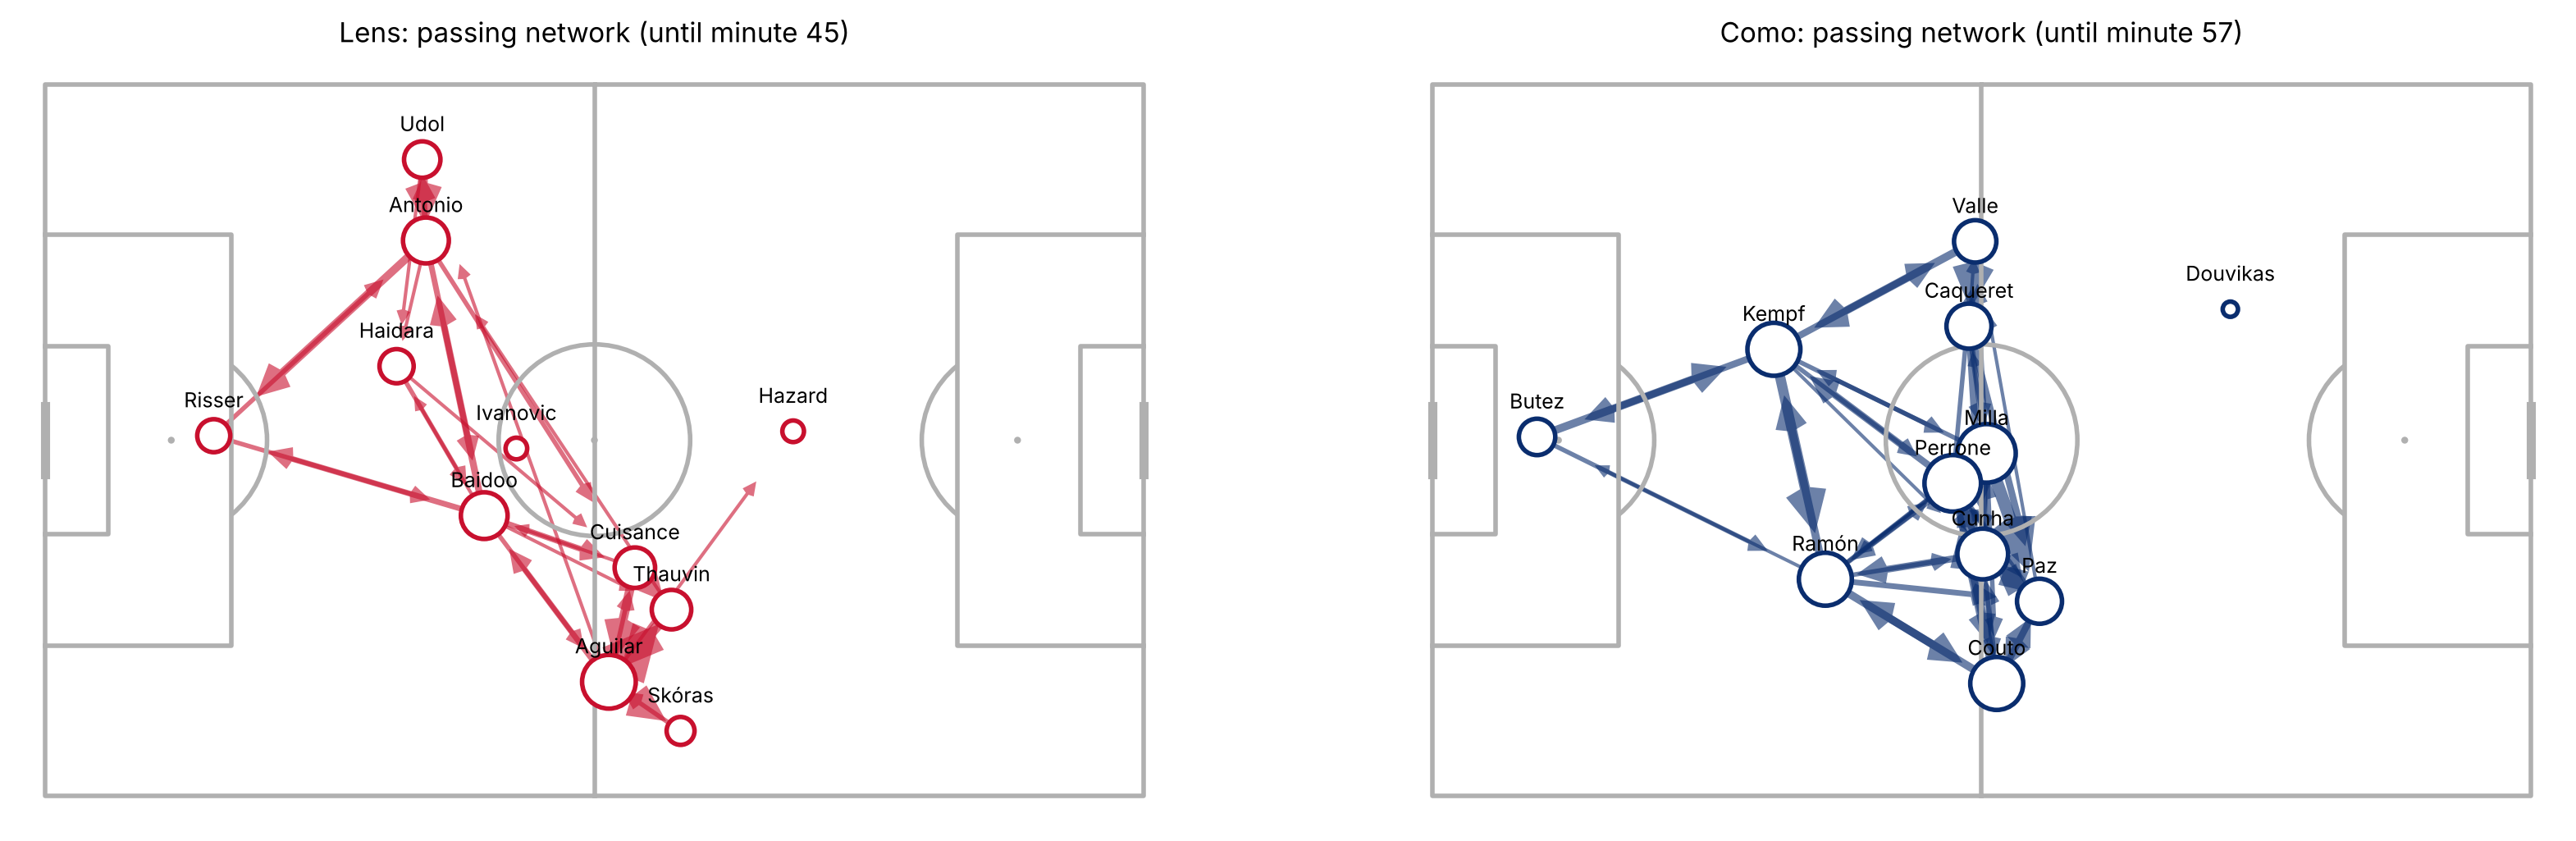

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_passing_network(axes[0], HOME)
draw_passing_network(axes[1], AWAY)
plt.show()

## Zone 14 and the half-spaces

In [18]:
def draw_zone14(ax, team):
    p = completed_passes(team)
    p = p[~p["set_piece"]]

    in_z14 = p["end_x"].between(66.7, 83) & p["end_y"].between(33.3, 66.7)
    in_hs = p["end_x"].between(66.7, 100) & (
        p["end_y"].between(21.1, 36.8) | p["end_y"].between(63.2, 78.9)
    )
    z14 = p[in_z14]
    hs = p[in_hs]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    ax.add_patch(Rectangle((66.7, 33.3), 83 - 66.7, 66.7 - 33.3, color="gold", alpha=0.2, zorder=1))
    ax.add_patch(Rectangle((66.7, 21.1), 100 - 66.7, 36.8 - 21.1, color=COLOURS[team], alpha=0.15, zorder=1))
    ax.add_patch(Rectangle((66.7, 63.2), 100 - 66.7, 78.9 - 63.2, color=COLOURS[team], alpha=0.15, zorder=1))

    pitch.arrows(z14["x"], z14["y"], z14["end_x"], z14["end_y"], ax=ax, width=1.5,
                 headwidth=5, color="orange", zorder=3, label=f"Zone 14 ({len(z14)})")
    pitch.arrows(hs["x"], hs["y"], hs["end_x"], hs["end_y"], ax=ax, width=1.5,
                 headwidth=5, color=COLOURS[team], zorder=3, label=f"Half-spaces ({len(hs)})")

    ax.legend(loc="upper left", fontsize=10)
    ax.set_title(f"{team}: passes into zone 14 and the half-spaces")

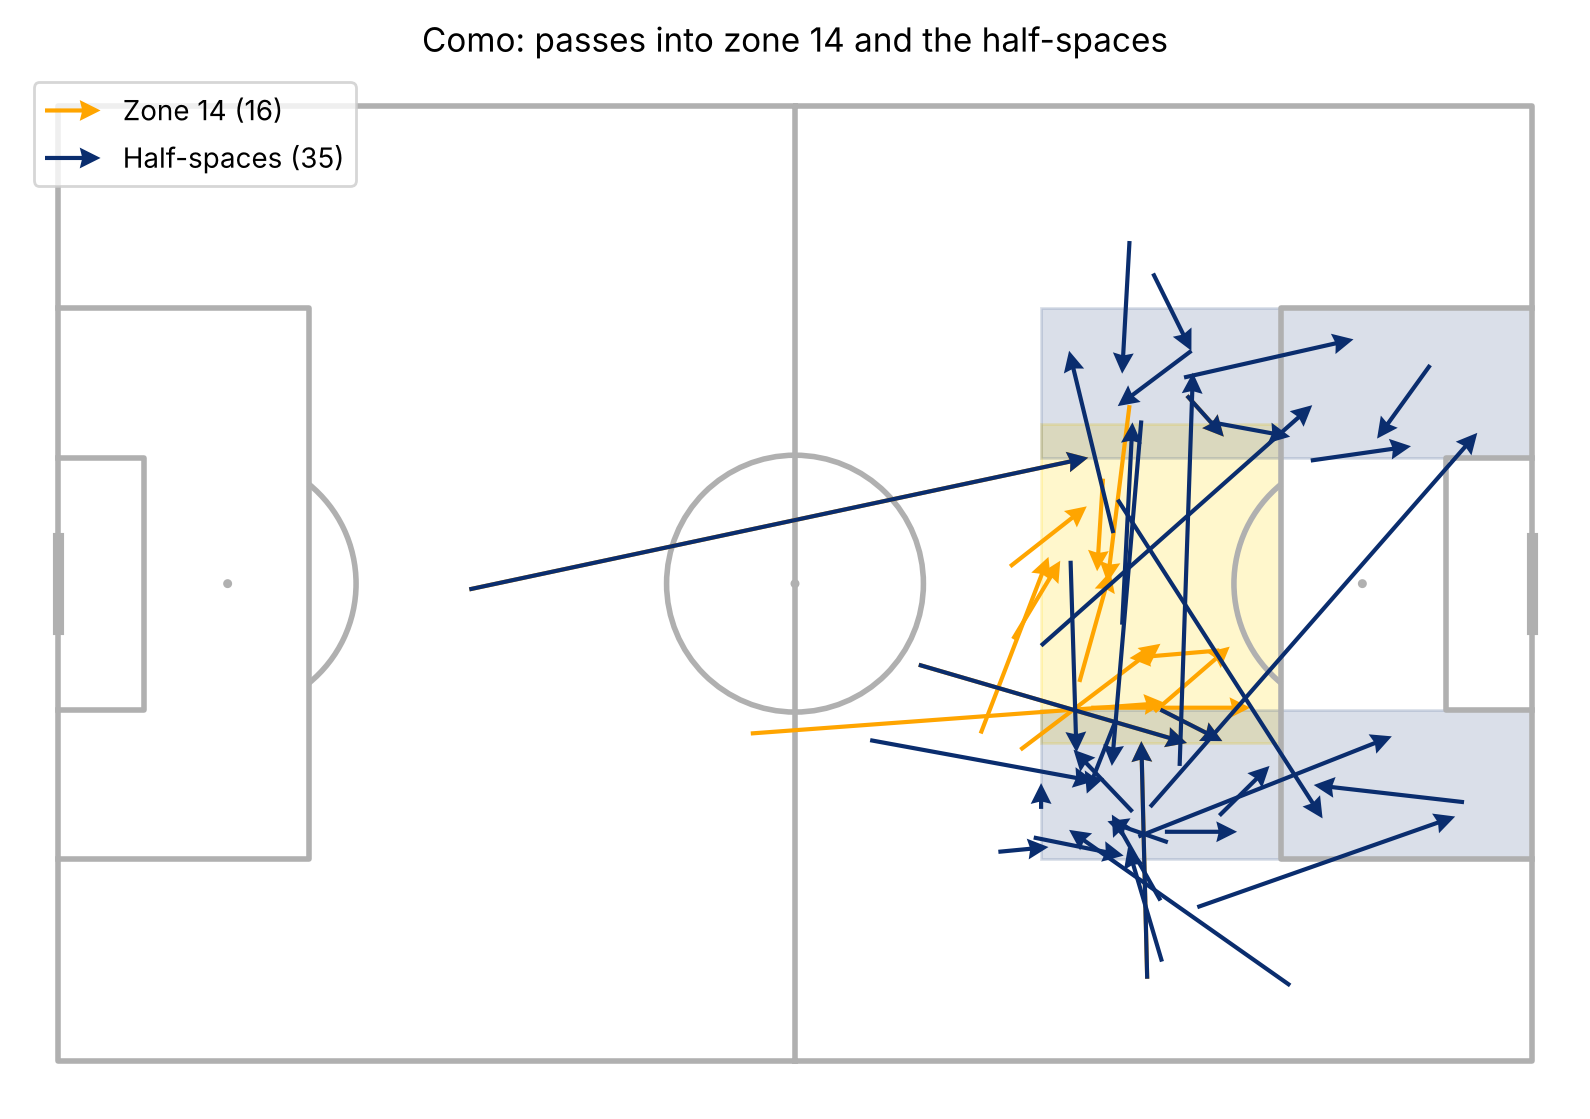

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_zone14(ax, AWAY)
plt.show()

## Match momentum (xT per minute)

In [20]:
def draw_momentum(ax):
    for team, sign in [(AWAY, 1), (HOME, -1)]:
        per_min = completed_passes(team).groupby("minute")["xt"].sum()
        ax.bar(per_min.index, sign * per_min.values, color=COLOURS[team],
               label=f"{team} ({per_min.sum():.2f} xT)")

        goals = events[(events["team"] == team) & (events["is_goal"] == True)]["minute"]
        for m in goals:
            ax.axvline(m, color=COLOURS[team], linestyle="--", linewidth=1.2, alpha=0.8)

    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Minute")
    ax.set_ylabel("xT added")
    ax.legend(loc="upper right", fontsize=10)
    ax.set_title("Match momentum by xT (dashed lines = goals)")

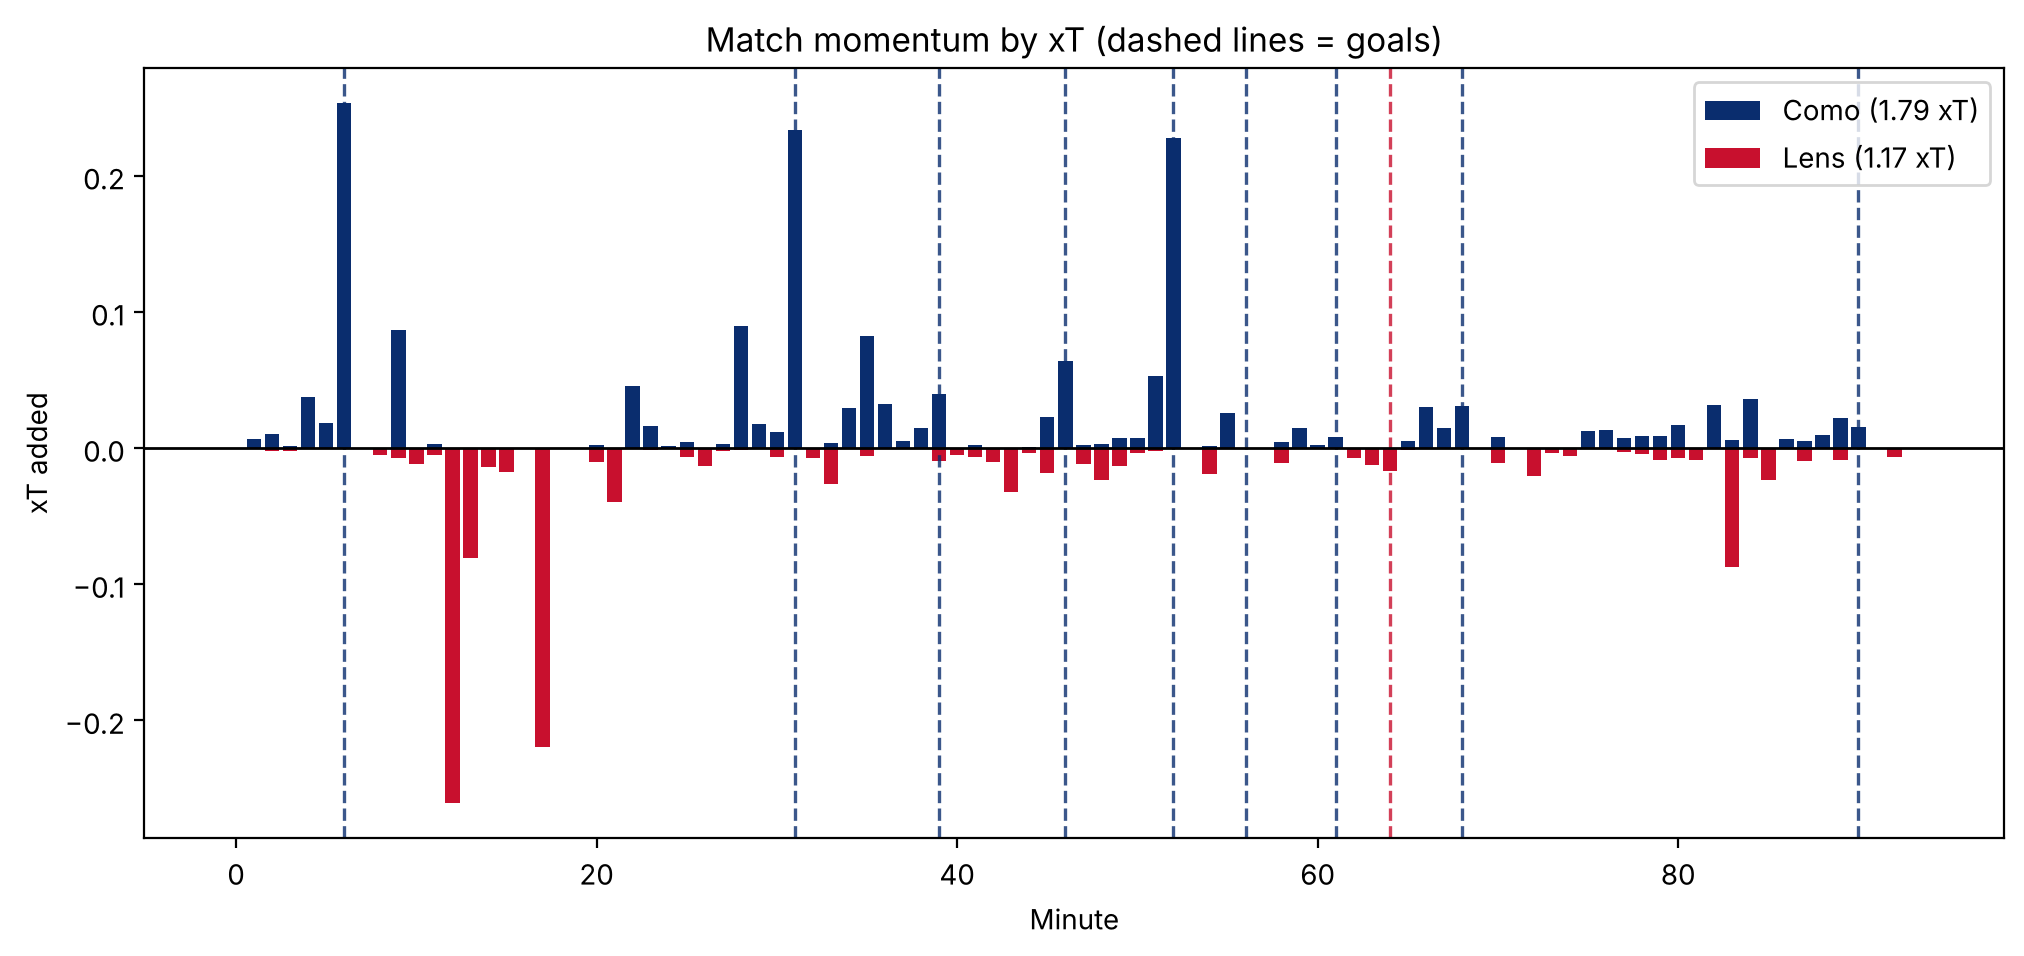

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
draw_momentum(ax)
plt.show()

## Match stats

In [22]:
def team_stats(team):
    d = events[events["team"] == team]
    passes = d[d["type"] == "Pass"]
    done = completed_passes(team)
    wins = d["type"].isin(["BallRecovery", "Interception"]) | ((d["type"] == "Tackle") & (d["outcome_type"] == "Successful"))
    return {
        "Goals": int((d["is_goal"] == True).sum()),
        "Shots": int((d["is_shot"] == True).sum()),
        "Shots on target": int(d["type"].isin(["SavedShot", "Goal"]).sum()),
        "Key passes": int(passes["qualifiers"].str.contains("KeyPass", na=False).sum()),
        "Passes": len(passes),
        "Pass completion %": round(len(done) / len(passes) * 100, 1),
        "Final-third passes": int((done["end_x"] >= 66.7).sum()),
        "Progressive passes": int((done["is_progressive"] & ~done["set_piece"]).sum()),
        "xT from passes": round(done["xt"].sum(), 2),
        "High turnovers": int((wins & (d["dist_start"] <= 40)).sum()),
    }


def draw_match_stats(ax):
    home, away = team_stats(HOME), team_stats(AWAY)
    labels = list(home)[::-1]

    # each bar is that team's share of the total, so different units sit on one scale
    for i, k in enumerate(labels):
        total = home[k] + away[k]
        h_share = home[k] / total if total else 0.5
        ax.barh(i, -h_share, color=COLOURS[HOME], height=0.38)
        ax.barh(i, 1 - h_share, color=COLOURS[AWAY], height=0.38)
        ax.text(-1.04, i, f"{home[k]:g}", ha="right", va="center", fontsize=14, fontweight="bold", color=COLOURS[HOME])
        ax.text(1.04, i, f"{away[k]:g}", ha="left", va="center", fontsize=14, fontweight="bold", color=COLOURS[AWAY])
        ax.text(0, i + 0.24, k, ha="center", va="bottom", fontsize=12)

    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-0.5, len(labels) - 0.1)
    ax.axis("off")
    ax.set_title(f"Match stats: {HOME} (left) v {AWAY} (right)")

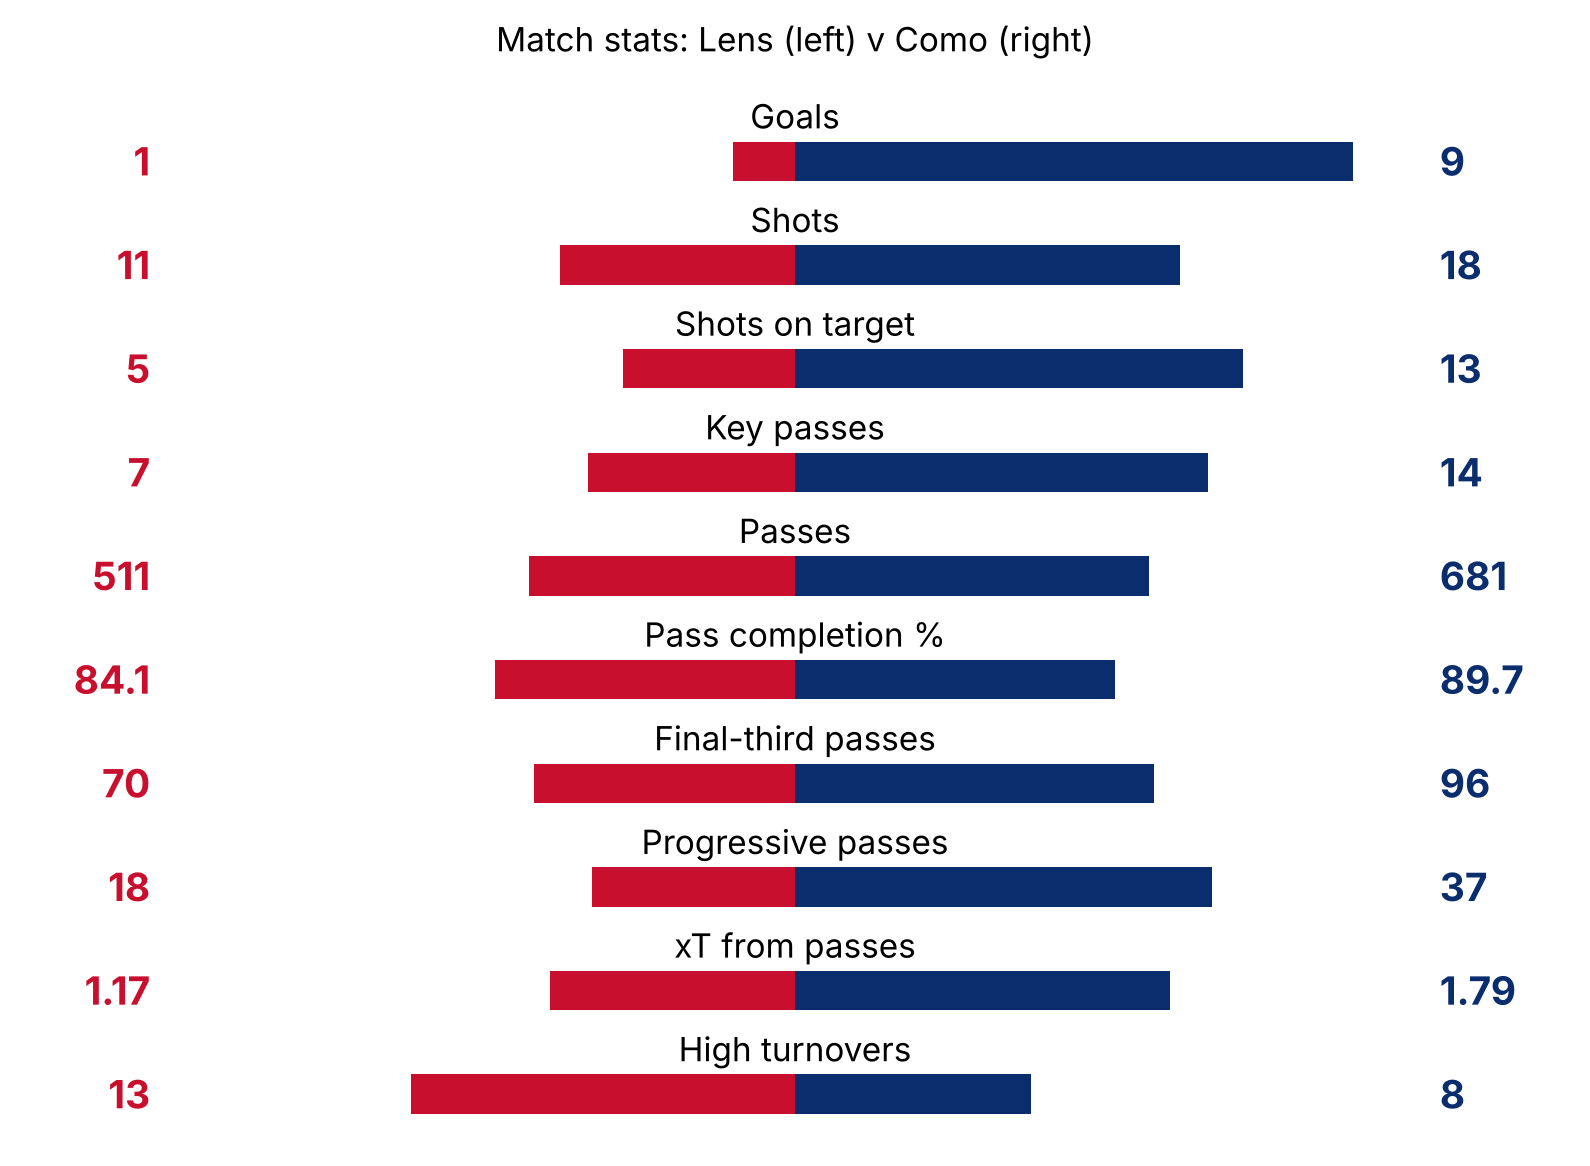

In [23]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_match_stats(ax)
plt.show()

## Man of the match: Tasos Douvikas

Touches, carries, completed and incomplete passes, and goals. Carries aren't in the data, so they're built from consecutive touches: the same team keeps the ball in the same half, the previous action succeeded, and the player moved it 3–60 m.

In [24]:
def player_summary(player):
    pe = events[events["player"] == player]
    passes = pe[pe["type"] == "Pass"]

    touches = events[events["is_touch"] == True].copy()
    touches["prev_team"] = touches["team"].shift(1)
    touches["prev_period"] = touches["period"].shift(1)
    touches["prev_outcome"] = touches["outcome_type"].shift(1)
    touches["carry_start_x"] = touches["end_x"].fillna(touches["x"]).shift(1)
    touches["carry_start_y"] = touches["end_y"].fillna(touches["y"]).shift(1)
    dx = (touches["x"] - touches["carry_start_x"]) * 1.05
    dy = (touches["y"] - touches["carry_start_y"]) * 0.68
    touches["carry_dist"] = np.sqrt(dx**2 + dy**2)
    is_carry = (
        (touches["team"] == touches["prev_team"])
        & (touches["period"] == touches["prev_period"])
        & (touches["prev_outcome"] == "Successful")
        & (touches["carry_dist"].between(3, 60))
    )

    return {
        "touches": pe[pe["is_touch"] == True],
        "carries": touches[is_carry & (touches["player"] == player)],
        "completed": passes[passes["outcome_type"] == "Successful"],
        "incomplete": passes[passes["outcome_type"] == "Unsuccessful"],
        "shots": pe[pe["is_shot"] == True],
        "goals": pe[pe["is_goal"] == True],
        "assists": passes[passes["qualifiers"].str.contains("IntentionalGoalAssist", na=False)],
        "minutes": pe[pe["type"] == "SubstitutionOff"]["minute"].min(),
    }


def draw_player_performance(ax, player):
    s = player_summary(player)
    mins = s["minutes"] if pd.notna(s["minutes"]) else 90

    pitch = Pitch(pitch_type="opta", pitch_color="#0e1117", line_color="#888888", line_zorder=1)
    pitch.draw(ax=ax)

    pitch.scatter(s["touches"]["x"], s["touches"]["y"], ax=ax, s=80, color="yellow", alpha=0.35,
                  zorder=2, label=f"Touches ({len(s['touches'])})")
    pitch.arrows(s["carries"]["carry_start_x"], s["carries"]["carry_start_y"],
                 s["carries"]["x"], s["carries"]["y"], ax=ax, color="deepskyblue", width=2,
                 zorder=3, label=f"Carries ({len(s['carries'])})")
    pitch.arrows(s["completed"]["x"], s["completed"]["y"], s["completed"]["end_x"], s["completed"]["end_y"],
                 ax=ax, color="white", width=2, zorder=4, label=f"Completed passes ({len(s['completed'])})")
    pitch.arrows(s["incomplete"]["x"], s["incomplete"]["y"], s["incomplete"]["end_x"], s["incomplete"]["end_y"],
                 ax=ax, color="red", width=2, zorder=4, label=f"Incomplete passes ({len(s['incomplete'])})")
    pitch.scatter(s["goals"]["x"], s["goals"]["y"], ax=ax, s=500, marker="football",
                  zorder=5, label=f"Goals ({len(s['goals'])})")

    ax.legend(loc="upper left", fontsize=9, facecolor="#0e1117", labelcolor="white", edgecolor="#888888")
    ax.set_title(f"Man of the match: {player} - {len(s['goals'])} goals from {len(s['shots'])} shots, "
                 f"{len(s['assists'])} assist, {mins} minutes")
    return s


def draw_player_card(ax, player):
    s = player_summary(player)
    ax.axis("off")
    ax.text(0.5, 0.97, "MAN OF THE MATCH", ha="center", va="top", fontsize=20, fontweight="bold",
            color=COLOURS[AWAY], transform=ax.transAxes)
    ax.text(0.5, 0.88, player, ha="center", va="top", fontsize=30, fontweight="bold", transform=ax.transAxes)

    rows = [("Goals", len(s["goals"])), ("Shots", len(s["shots"])), ("Assists", len(s["assists"])),
            ("Minutes played", int(s["minutes"]) if pd.notna(s["minutes"]) else 90),
            ("Touches", len(s["touches"])), ("Carries", len(s["carries"])),
            ("Passes completed", f"{len(s['completed'])}/{len(s['completed']) + len(s['incomplete'])}")]
    for i, (label, value) in enumerate(rows):
        yy = 0.74 - i * 0.098
        ax.text(0.34, yy, str(value), ha="right", va="center", fontsize=34, fontweight="bold",
                color=COLOURS[AWAY], transform=ax.transAxes)
        ax.text(0.39, yy, label, ha="left", va="center", fontsize=20, transform=ax.transAxes)

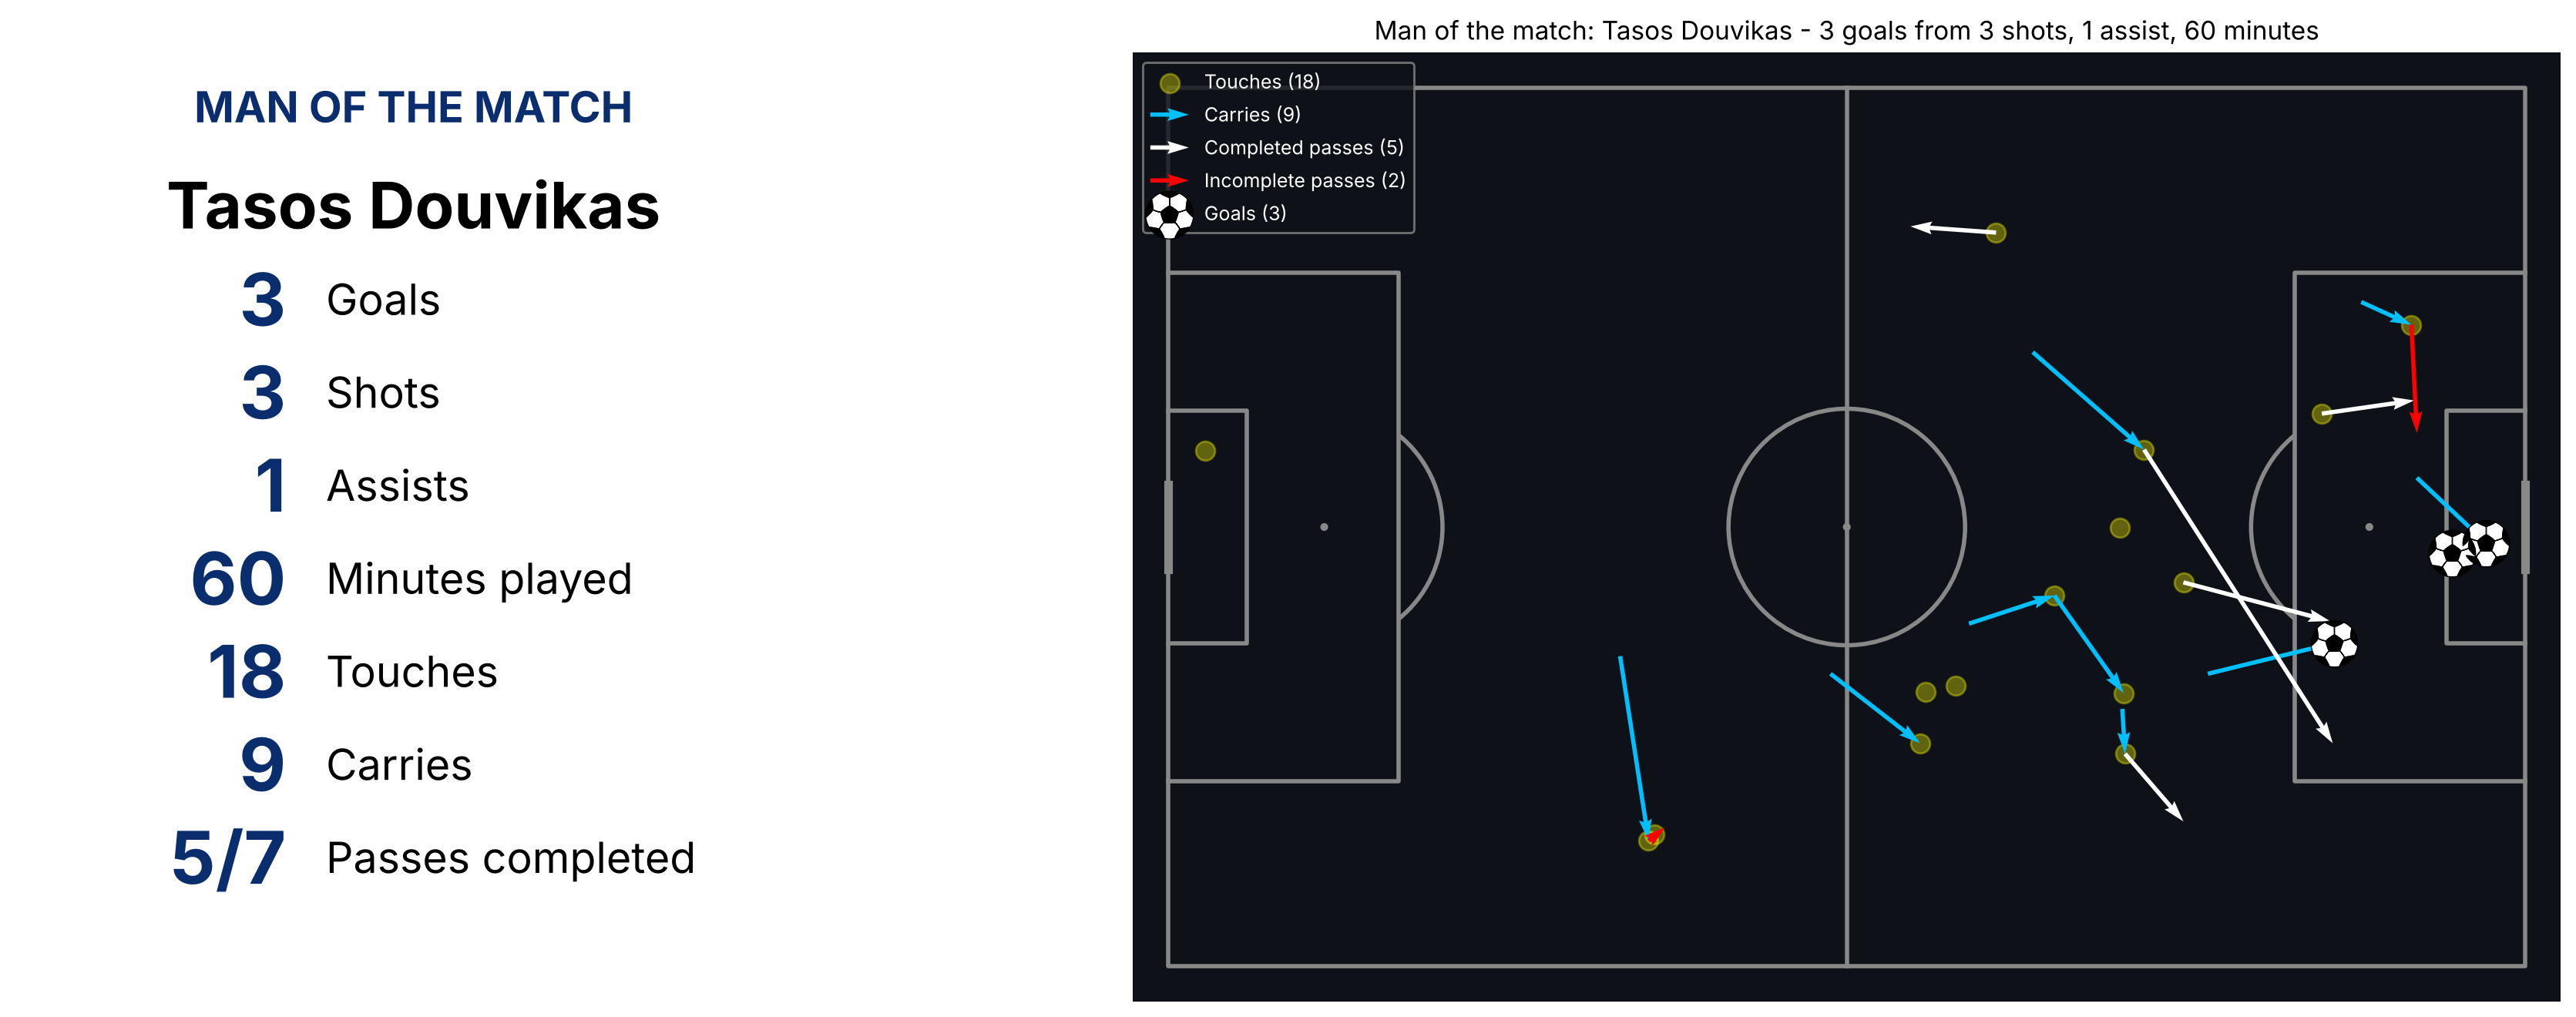

{'touches': 18,
 'carries': 9,
 'completed': 5,
 'incomplete': 2,
 'shots': 3,
 'goals': 3,
 'assists': 1,
 'minutes': np.int64(60)}

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={"width_ratios": [1, 2]})
draw_player_card(axes[0], STAR)
s = draw_player_performance(axes[1], STAR)
plt.show()
{k: len(v) if hasattr(v, "__len__") else v for k, v in s.items()}

## Key takeaways

In [26]:
TAKEAWAYS = [
    "A joint Champions League record: Como's 9 goals equal the most by one team in a match (Bayern 9-2 "
    "Dinamo Zagreb, 2024), and the 8-goal margin equals the biggest win (Liverpool, Real Madrid) and is "
    "the competition's biggest away win.",
    "Ruthless finishing: Como scored 9 from 18 shots (13 on target). Lens scored 1 from 11 (5 on target).",
    "Tasos Douvikas was man of the match: a hat-trick and an assist in 60 minutes, scoring with all 3 of his "
    "shots from just 18 touches.",
    "Goals from everywhere: 7 different scorers, 3-0 at half-time, then 6 more after the break, "
    "including 3 from substitutes (Liberali, Baturina, Papaccioli).",
    "Como had the ball and used it: 681 passes to 511 (89.7% v 84.1% completed), "
    "and 96 v 70 completed passes into the final third.",
    "They found the dangerous spaces: 37 progressive passes to Lens's 18, with 16 passes into Zone 14 "
    "and 35 into the half-spaces (Lens: 6 and 8).",
    "xT was much closer (1.79 v 1.17) than the score, which shows how clinical Como were. "
    "Luis Milla led all players with 0.65 xT from his passing.",
    "Lens pressed high (13 high turnovers to Como's 8) but couldn't turn it into chances: "
    "7 key passes to Como's 14.",
]


def draw_takeaways(ax):
    ax.axis("off")
    ax.text(0.0, 1.0, "KEY TAKEAWAYS", fontsize=26, fontweight="bold", va="top",
            color=COLOURS[AWAY], transform=ax.transAxes)

    half = (len(TAKEAWAYS) + 1) // 2
    for col, points in enumerate([TAKEAWAYS[:half], TAKEAWAYS[half:]]):
        text = "\n\n".join(textwrap.fill("• " + p, width=70, subsequent_indent="   ") for p in points)
        ax.text(0.0 + col * 0.5, 0.82, text, fontsize=19, va="top", linespacing=1.35,
                transform=ax.transAxes)

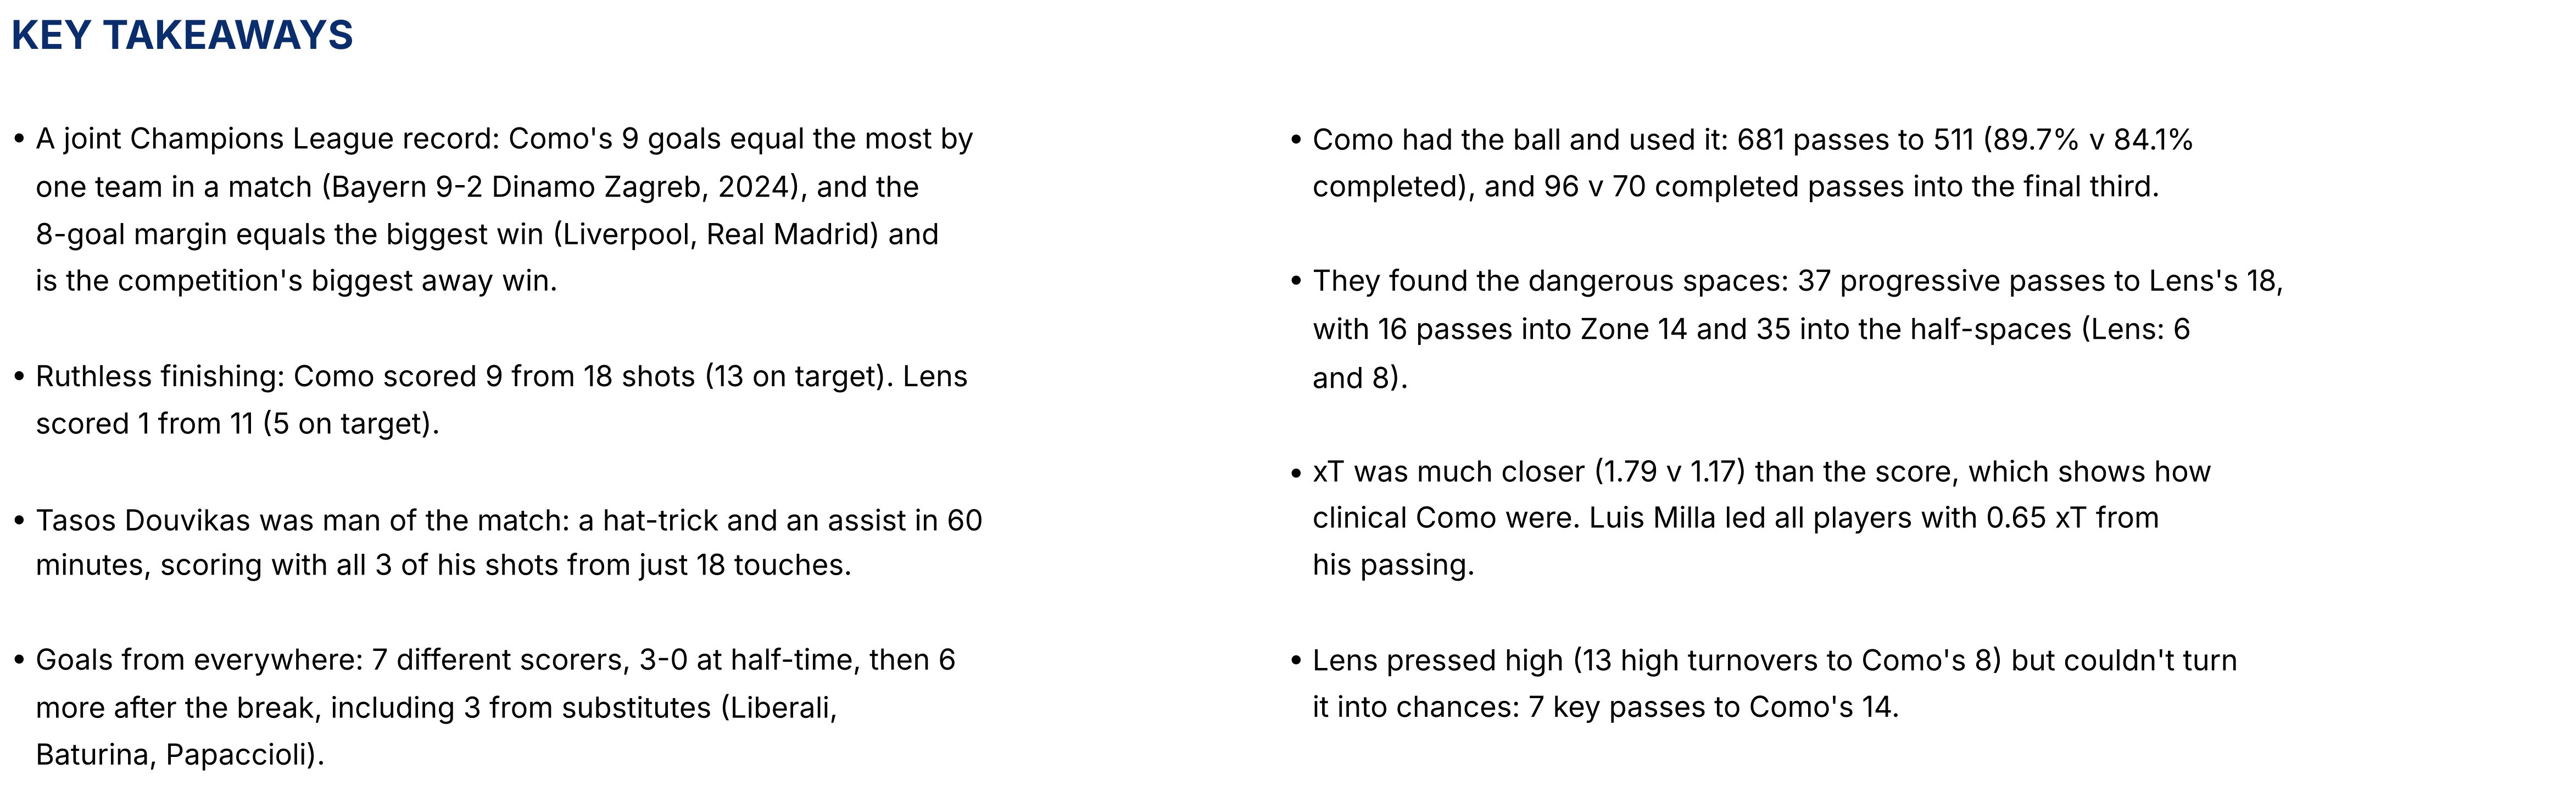

In [27]:
fig, ax = plt.subplots(figsize=(30, 7))
draw_takeaways(ax)
plt.show()

## The full report

Lens on the left, Como on the right, shared charts in the middle; match stats, man of the match and key takeaways at the bottom.

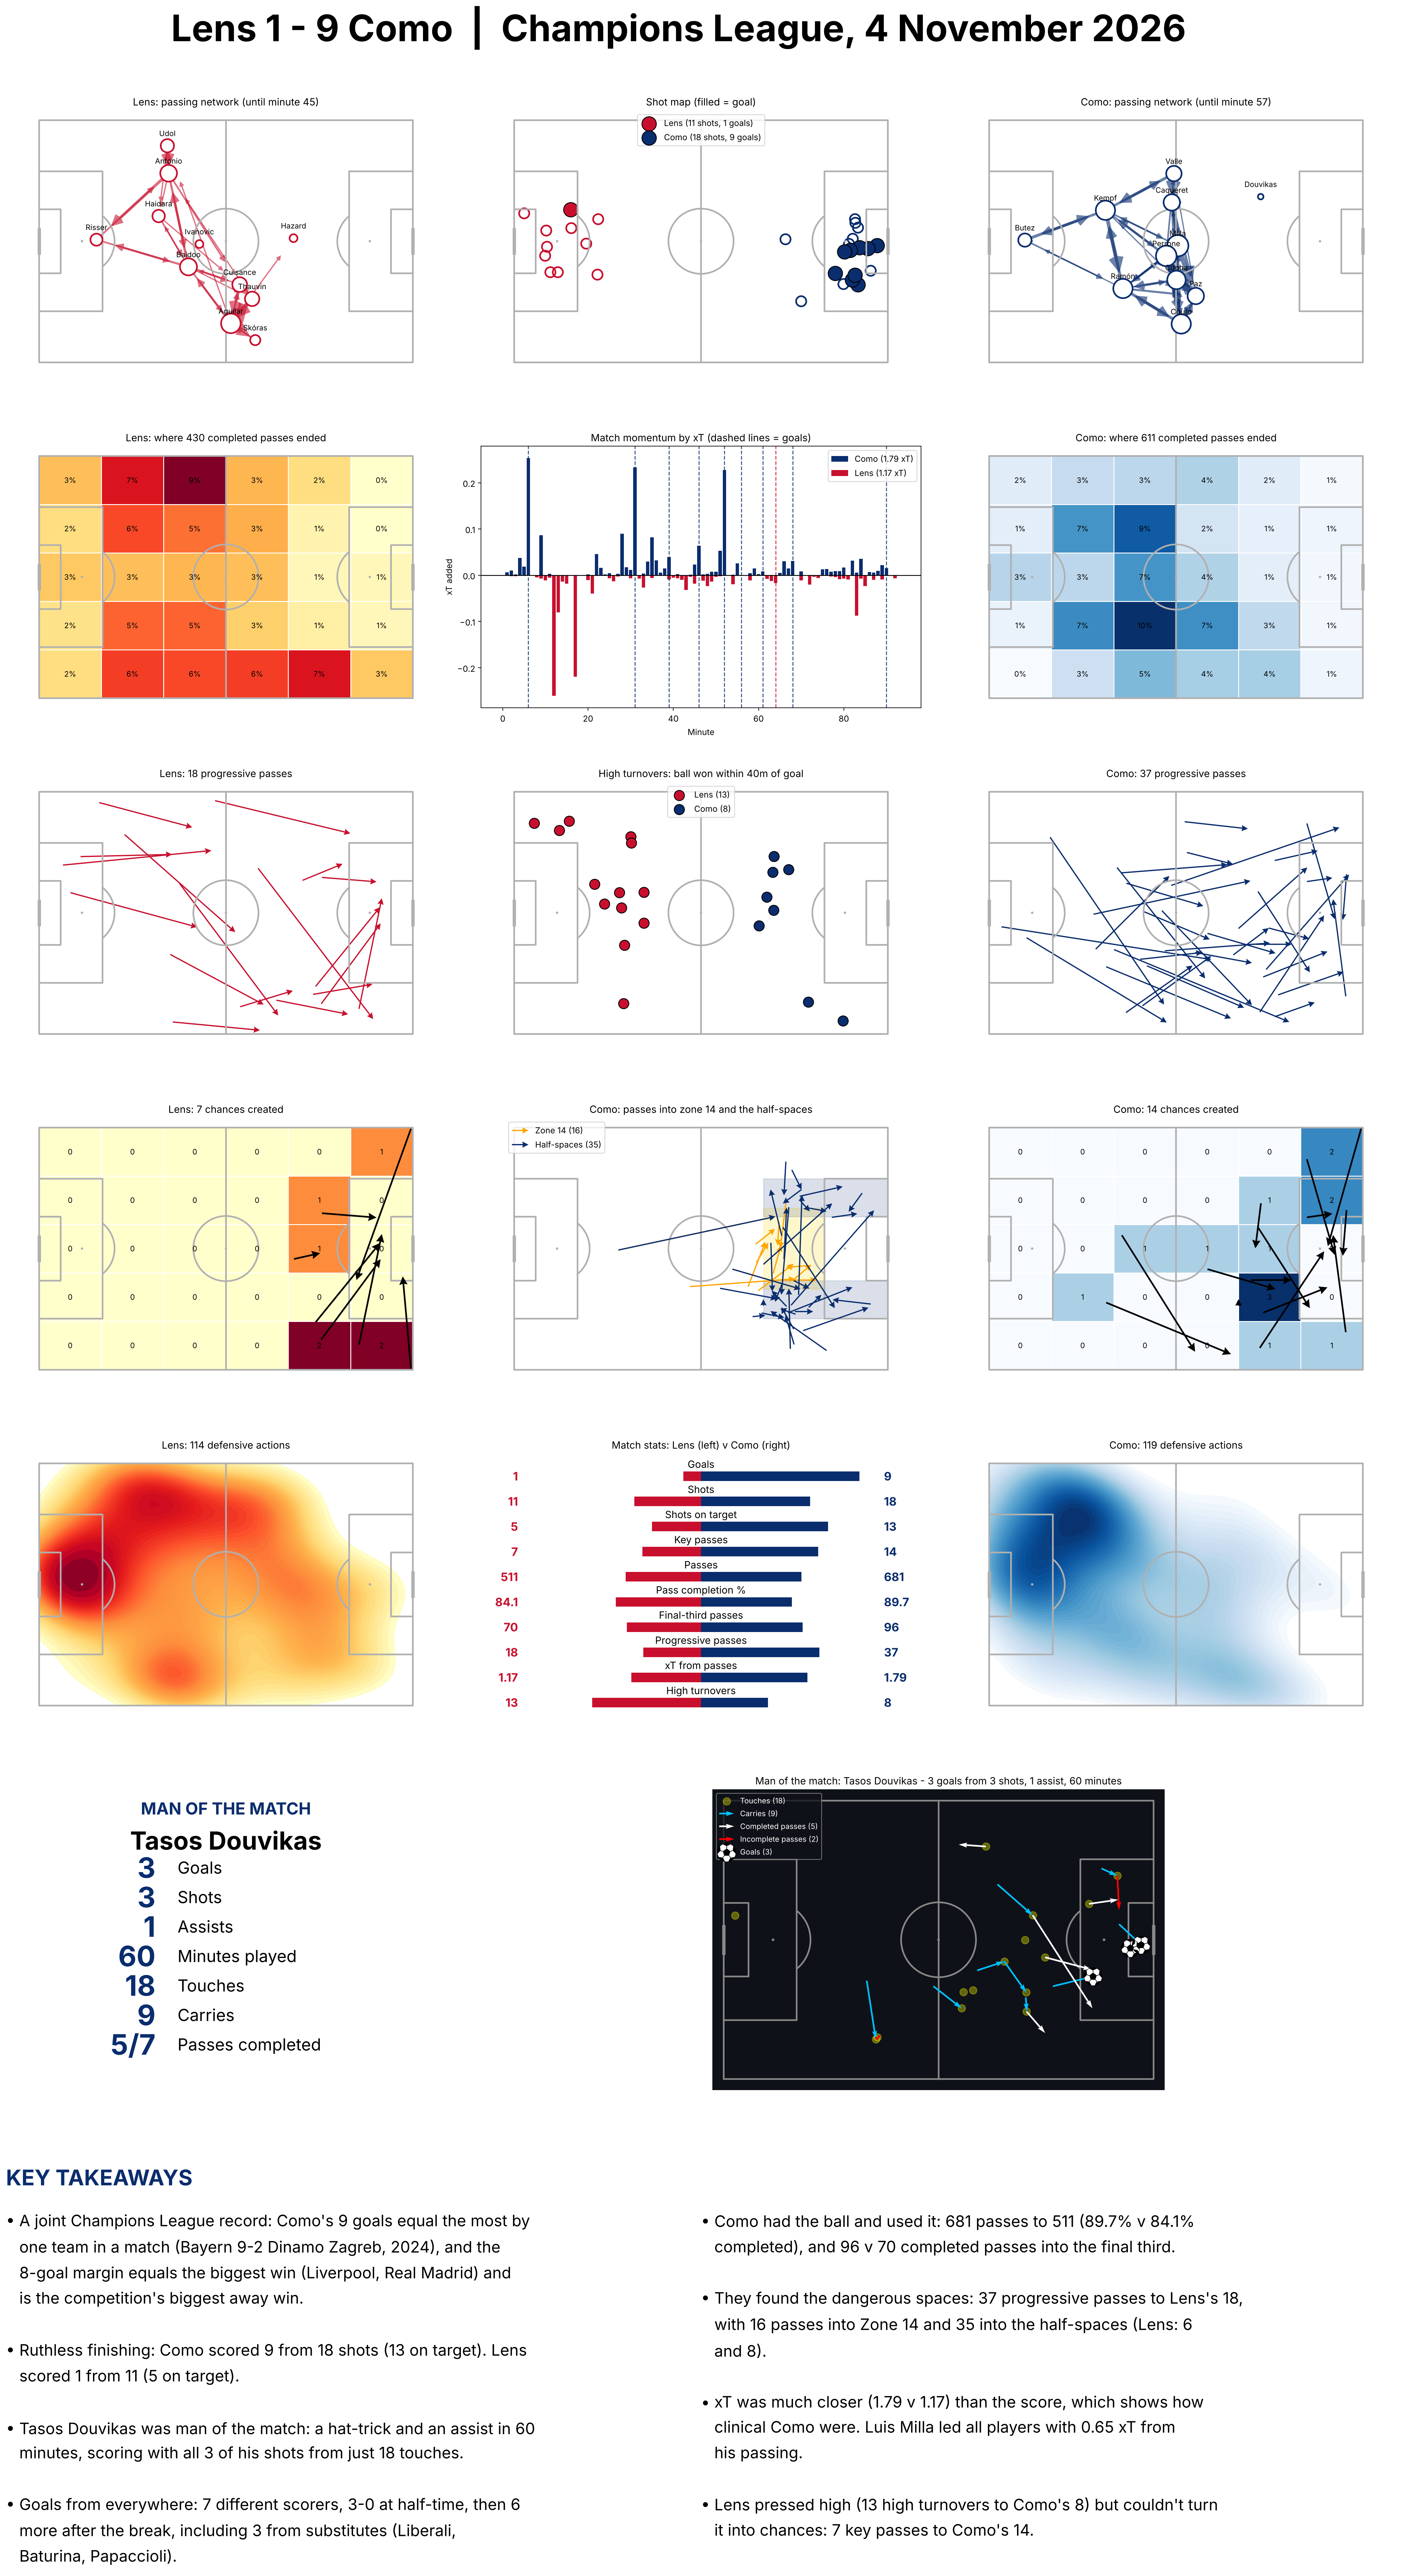

In [28]:
fig = plt.figure(figsize=(30, 50))
gs = fig.add_gridspec(7, 3, height_ratios=[1, 1, 1, 1, 1, 1.15, 0.95], hspace=0.28, wspace=0.08)
ax = lambda r, c: fig.add_subplot(gs[r, c])

# row 0
draw_passing_network(ax(0, 0), HOME)
draw_shot_map_both(ax(0, 1))
draw_passing_network(ax(0, 2), AWAY)

# row 1
draw_pass_end_zones(ax(1, 0), HOME)
draw_momentum(ax(1, 1))
draw_pass_end_zones(ax(1, 2), AWAY)

# row 2
draw_progressive(ax(2, 0), HOME)
draw_high_turnovers(ax(2, 1))
draw_progressive(ax(2, 2), AWAY)

# row 3
draw_chance_creation(ax(3, 0), HOME)
draw_zone14(ax(3, 1), AWAY)
draw_chance_creation(ax(3, 2), AWAY)

# row 4
draw_defensive_block(ax(4, 0), HOME)
draw_match_stats(ax(4, 1))
draw_defensive_block(ax(4, 2), AWAY)

# row 5: man of the match - stat card + his actions on the pitch
draw_player_card(ax(5, 0), STAR)
draw_player_performance(fig.add_subplot(gs[5, 1:]), STAR)

# row 6: key takeaways, full width
draw_takeaways(fig.add_subplot(gs[6, :]))

# header
home_goals = len(events[(events["team"] == HOME) & (events["is_goal"] == True)])
away_goals = len(events[(events["team"] == AWAY) & (events["is_goal"] == True)])
fig.suptitle(f"{HOME} {home_goals} - {away_goals} {AWAY}  |  Champions League, 4 November 2026",
             fontsize=44, fontweight="bold", y=0.915)

fig.savefig("match_report.png", dpi=100, bbox_inches="tight", facecolor="white")
plt.show()